# Notebook 09 — Final forecasting table: leak-free, no author features


In [1]:
# ==== 0. Environment and configuration =============================================
import os, sys, json, time, warnings
warnings.filterwarnings("ignore", category=UserWarning)
IN_COLAB = "google.colab" in sys.modules
SMOKE_TEST = bool(int(os.environ.get("HOD_SMOKE", "0")))   # True = tiny synthetic dry run (CPU is fine)

CONFIG = dict(
    BASE_DIR   = "/content/drive/MyDrive/PhD/reddit_opinion_research",
    ITEM_KEYS  = {},        # e.g. {"rows": "emb_idx", "parent": "parent_idx"} if auto-mapping fails
    GOLD_PATH  = None,      # path to the 916-doc gold set (doc_id + gold sentiment + gold emotion); None = auto-discover
    GOLD_SENT_COL = None, GOLD_EMO_COL = None,
    CORPUS_PATH = None,     # processed_v2/text_corpus.parquet (doc_id mapping + leak-free author features); None = default
    CLEAN_USE_SCORE = True, # keep avg_score (pre-cutoff documents only) in the clean author features
    AUTHOR_FEATURES = "none",  # default for all models: "none" (v4 decision) or "clean"
    IMPORT_FROM = "nb09_v3",   # reuse identical (model, seed) runs from this earlier results folder
    OUT_DIR    = None,      # None = <BASE_DIR>/processed_v2/results/nb09_v3 (earlier runs kept)
    # ---- model / training: same backbone size as notebooks 05-08 ------------------------
    D_MODEL = 128, N_LAYERS = 4, N_STATE = 16, DROPOUT = 0.0, LR = 1e-3, WD = 0.01,   # notebook 05: no dropout
    BATCH_SIZE = 32,        # hyperedges per length-bucketed batch, as in notebook 05
    MAX_EPOCHS = 30, PATIENCE = 5, BATCH_TOKENS = 8192, AMP = False, SCAN_MODE = "pjump",  # notebook 05: fp32
    # ---- experiment ---------------------------------------------------------------------
    SEEDS  = [0, 1, 2, 3, 4],
    MODELS = ["ssm_tree", "ssm_dual", "ssm_chain", "parent_mlp", "gru_tree", "anc_transformer", "chain_transformer",
              "gru_chain", "treelstm_topdown", "gat_topdown", "ssm_tree_hetero", "ssm_tree_leaky", "ssm_tree_cleanfeat"],
    N_BOOT = 2000,
)
if SMOKE_TEST:
    CONFIG.update(BASE_DIR="/tmp/hod_smoke09", D_MODEL=32, N_LAYERS=2, N_STATE=8, MAX_EPOCHS=2, PATIENCE=2,
                  BATCH_SIZE=16, SEEDS=[0, 1])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
if CONFIG["OUT_DIR"] is None:
    CONFIG["OUT_DIR"] = os.path.join(CONFIG["BASE_DIR"], "processed_v2", "results", "nb09_v4")
os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)
print(json.dumps(CONFIG, indent=1, default=str))


Mounted at /content/drive
{
 "BASE_DIR": "/content/drive/MyDrive/PhD/reddit_opinion_research",
 "ITEM_KEYS": {},
 "GOLD_PATH": null,
 "GOLD_SENT_COL": null,
 "GOLD_EMO_COL": null,
 "CORPUS_PATH": null,
 "CLEAN_USE_SCORE": true,
 "AUTHOR_FEATURES": "none",
 "IMPORT_FROM": "nb09_v3",
 "OUT_DIR": "/content/drive/MyDrive/PhD/reddit_opinion_research/processed_v2/results/nb09_v4",
 "D_MODEL": 128,
 "N_LAYERS": 4,
 "N_STATE": 16,
 "DROPOUT": 0.0,
 "LR": 0.001,
 "WD": 0.01,
 "BATCH_SIZE": 32,
 "MAX_EPOCHS": 30,
 "PATIENCE": 5,
 "BATCH_TOKENS": 8192,
 "AMP": false,
 "SCAN_MODE": "pjump",
 "SEEDS": [
  0,
  1,
  2,
  3,
  4
 ],
 "MODELS": [
  "ssm_tree",
  "ssm_dual",
  "ssm_chain",
  "parent_mlp",
  "gru_tree",
  "anc_transformer",
  "chain_transformer",
  "gru_chain",
  "treelstm_topdown",
  "gat_topdown",
  "ssm_tree_hetero",
  "ssm_tree_leaky",
  "ssm_tree_cleanfeat"
 ],
 "N_BOOT": 2000
}


## 1. Shared code (`hod_core.py`)


In [2]:
%%writefile hod_core.py
# hod_core.py -- shared code for notebooks 09 (baselines) and 10 (parallel tree scan).
# Written to disk by the first code cell of each notebook so both notebooks use identical code.
import os, glob, json, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SENT_CLASSES = ["Negative", "Neutral", "Positive"]
EMO_CLASSES = ["Anger", "Joy", "Neutral", "Sadness", "Surprise"]   # Fear merged into Sadness
REL_ROOT, REL_POST, REL_COMMENT = 0, 1, 2
IGNORE = -100
N_REL = 3
BATCH_SIZE = None       # hyperedges per batch (notebook 05: 32); None = token-budget batching
DEFAULT_FEAT = "clean"  # author-feature bank used by models that don't name one ("none" = no author features)
FEATURE_BANK = {}       # name -> torch tensor [n_authors + 1, F] (last row = zeros for unknown authors)


def set_feature_bank(banks, device):
    """banks: {"clean": ndarray [n_authors, F], "leaky": ndarray [...], ...}. Models pick one via MODEL_SPECS."""
    FEATURE_BANK.clear()
    for name, mat in banks.items():
        m = np.asarray(mat, dtype=np.float32)
        FEATURE_BANK[name] = torch.from_numpy(np.vstack([m, np.zeros((1, m.shape[1]), np.float32)])).to(device)


def set_node_features(mat, device):
    """Backward-compatible single-matrix setter (registers it as the 'clean' bank)."""
    set_feature_bank({} if mat is None else {"clean": mat}, device)


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def build_author_features(text_corpus, temporal_edges, author_to_idx, cutoff=np.inf, sent_label_by_doc=None,
                          use_score=True):
    """Notebook 01b/04 author features, restricted to documents (and reply edges) created before `cutoff`.
    Definitions (01b): out_degree / in_degree = number of reply edges sent / received (self-replies excluded);
    n_posts / n_comments = documents authored; avg_score = mean Reddit score of the author's documents.
    If sent_label_by_doc is given (numeric -1/0/+1 per corpus row), avg_sentiment_score is appended (notebook 04's
    leaky column -- only used to verify the reconstruction). Transform: signed log1p, then z-score over authors."""
    tc = text_corpus[text_corpus["created_utc"] < cutoff]
    te = temporal_edges[temporal_edges["created_utc"] < cutoff]
    idx = pd.Index(list(author_to_idx.keys()))
    df = pd.DataFrame(index=idx)
    df["out_degree"] = te.groupby("source_author").size()
    df["in_degree"] = te.groupby("target_author").size()
    is_post = tc["parent_doc_id"].isna()
    df["n_posts"] = tc[is_post].groupby("author_hash").size()
    df["n_comments"] = tc[~is_post].groupby("author_hash").size()
    cols = ["out_degree", "in_degree", "n_posts", "n_comments"]
    if use_score and "score" in tc.columns:
        df["avg_score"] = tc.groupby("author_hash")["score"].mean(); cols.append("avg_score")
    if sent_label_by_doc is not None:
        lab = pd.Series(sent_label_by_doc, index=text_corpus.index)[tc.index]
        df["avg_sentiment_score"] = lab.groupby(tc["author_hash"]).mean(); cols.append("avg_sentiment_score")
    df = df[cols].fillna(0.0)
    order = np.argsort([author_to_idx[a] for a in df.index])
    X = signed_log1p(df.to_numpy(np.float64)[order])
    X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    active = int((df[["n_posts", "n_comments"]].sum(1) > 0).sum())
    return X.astype(np.float32), cols, active


def reply_edges_from_corpus(tc):
    """Fallback when temporal_edges.parquet is unavailable: author->parent-author reply edges from text_corpus."""
    auth = tc.set_index("doc_id")["author_hash"]
    e = tc[tc["parent_doc_id"].notna()][["author_hash", "parent_doc_id", "created_utc"]].copy()
    e["target_author"] = e["parent_doc_id"].map(auth)
    e = e[e["target_author"].notna() & (e["target_author"] != e["author_hash"])]
    return e.rename(columns={"author_hash": "source_author"})[["source_author", "target_author", "created_utc"]]


def configure(sent_classes=None, emo_classes=None, n_rel=None, batch_size=None, default_feat=None):
    """Set class lists / number of relation types / batch size / default author features."""
    global SENT_CLASSES, EMO_CLASSES, N_REL, BATCH_SIZE, DEFAULT_FEAT
    if default_feat is not None: DEFAULT_FEAT = default_feat
    if batch_size is not None: BATCH_SIZE = int(batch_size)
    if sent_classes is not None: SENT_CLASSES = list(sent_classes)
    if emo_classes is not None: EMO_CLASSES = list(emo_classes)
    if n_rel is not None: N_REL = int(n_rel)


# =====================================================================================
# 1. Artifact discovery and loading
# =====================================================================================
def find_file(base_dir, patterns, required=True, exclude=()):
    hits = []
    for pat in patterns:
        hits += glob.glob(os.path.join(base_dir, "**", pat), recursive=True)
    hits = sorted({h for h in hits if not any(e in h for e in exclude)}, key=lambda p: (len(p), p))
    if not hits:
        if required:
            raise FileNotFoundError(f"No file matching {patterns} under {base_dir}")
        return None
    if len(hits) > 1:
        print(f"  [find_file] several matches for {patterns}; using the first, override in CONFIG if wrong:")
        for h in hits[:6]:
            print("     ", h)
    return hits[0]


def _pick_col(cols, must, priority, forbid=("prob", "score", "conf", "logit", "gold")):
    cands = [c for c in cols if must in c.lower() and not any(f in c.lower() for f in forbid)]
    for p in priority:
        for c in cands:
            if c.lower() == p:
                return c
    return cands[0] if cands else None


def encode_labels(series, classes, merge=None):
    """Map string labels to ids in `classes` order (case-insensitive); ints are kept as-is."""
    if pd.api.types.is_numeric_dtype(series):
        out = series.fillna(IGNORE).astype(np.int64).to_numpy()
        return out
    lut = {c.lower(): i for i, c in enumerate(classes)}
    merge = {k.lower(): v.lower() for k, v in (merge or {}).items()}
    def f(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return IGNORE
        v = str(v).strip().lower()
        v = merge.get(v, v)
        return lut.get(v, IGNORE)
    out = series.map(f).to_numpy().astype(np.int64)
    unknown = sorted(set(series[out == IGNORE].dropna().astype(str).str.lower()) - {""})
    if unknown:
        print(f"  [encode_labels] WARNING unmapped values set to IGNORE: {unknown[:10]}")
    return out


def load_artifacts(cfg):
    """Returns corpus DataFrame (row i <-> embedding row i), embedding memmap, sentiment ids, emotion ids."""
    base = cfg["BASE_DIR"]
    corpus_path = cfg.get("CORPUS_PATH") or find_file(base, ["processed_v2/text_corpus.parquet", "text_corpus.parquet"],
                                                       exclude=("labeled",))
    labeled_path = cfg.get("LABELED_PATH") or find_file(base, ["text_corpus_labeled_finetuned.parquet"])
    emb_path = cfg.get("EMB_PATH") or find_file(base, ["dziribert_embeddings.npy"])
    print("corpus :", corpus_path); print("labeled:", labeled_path); print("emb    :", emb_path)

    corpus = pd.read_parquet(corpus_path)
    need = ["doc_id", "created_utc", "author_hash", "thread_id", "parent_doc_id"]
    miss = [c for c in need if c not in corpus.columns]
    if miss:
        raise KeyError(f"corpus is missing {miss}; columns = {list(corpus.columns)}")
    corpus["doc_id"] = corpus["doc_id"].astype(str)
    corpus["parent_doc_id"] = corpus["parent_doc_id"].where(corpus["parent_doc_id"].notna(), None)
    corpus["parent_doc_id"] = corpus["parent_doc_id"].map(lambda v: None if v is None or str(v) in ("", "nan", "None") else str(v))
    if np.issubdtype(corpus["created_utc"].dtype, np.datetime64):
        corpus["created_utc"] = corpus["created_utc"].astype("int64") // 10**9
    corpus["created_utc"] = corpus["created_utc"].astype(np.float64)

    emb = np.load(emb_path, mmap_mode="r")
    if emb.shape[0] != len(corpus):
        raise ValueError(f"embedding rows {emb.shape[0]} != corpus rows {len(corpus)}")

    lab = pd.read_parquet(labeled_path)
    lab["doc_id"] = lab["doc_id"].astype(str)
    sent_col = cfg.get("SENT_COL") or _pick_col(lab.columns, "sent", ["sentiment_ft", "sentiment_finetuned", "sentiment_pred",
                                                                      "sentiment_label_ft", "sentiment", "sentiment_label"])
    emo_col = cfg.get("EMO_COL") or _pick_col(lab.columns, "emo", ["emotion_ft", "emotion_finetuned", "emotion_pred",
                                                                   "emotion_label_ft", "emotion", "emotion_label"])
    print(f"label columns -> sentiment: {sent_col!r}, emotion: {emo_col!r}  (override SENT_COL/EMO_COL if wrong)")
    if sent_col is None or emo_col is None:
        raise KeyError(f"could not detect label columns in {list(lab.columns)}")

    # ---- alignment verification (row-for-row identity, as in Section 5.3 of the paper) ----
    same_order = len(lab) == len(corpus) and (lab["doc_id"].to_numpy() == corpus["doc_id"].to_numpy()).all()
    if same_order:
        print("alignment check: labeled file and corpus have identical doc_id order  [OK]")
        lab_al = lab
    else:
        print("alignment check: labeled order differs from corpus -> re-indexing labels by doc_id")
        lab_al = lab.drop_duplicates("doc_id").set_index("doc_id").reindex(corpus["doc_id"]).reset_index()
        n_missing = lab_al[sent_col].isna().sum()
        print(f"  docs without a label after re-indexing: {n_missing}")
    sent = encode_labels(lab_al[sent_col], SENT_CLASSES)
    emo = encode_labels(lab_al[emo_col], EMO_CLASSES, merge={"Fear": "Sadness"})
    print(f"labels: sentiment classes {np.unique(sent[sent >= 0])}, emotion classes {np.unique(emo[emo >= 0])}")
    return corpus, emb, sent, emo


def load_gold(cfg, corpus):
    path = cfg.get("GOLD_PATH")
    if path is None:
        path = find_file(cfg["BASE_DIR"], ["*gold*.parquet", "*gold*.csv", "*annot*.parquet", "*annot*.csv"], required=False)
    if path is None:
        print("gold set: not found (set GOLD_PATH to enable the gold-label evaluation)")
        return None
    g = pd.read_parquet(path) if path.endswith(".parquet") else pd.read_csv(path)
    idc = "doc_id" if "doc_id" in g.columns else next((c for c in g.columns if "id" in c.lower()), None)
    sc = cfg.get("GOLD_SENT_COL") or _pick_col(g.columns, "sent", ["gold_sentiment", "sentiment", "sentiment_label"], forbid=("prob", "score", "pred"))
    ec = cfg.get("GOLD_EMO_COL") or _pick_col(g.columns, "emo", ["gold_emotion", "emotion", "emotion_label"], forbid=("prob", "score", "pred"))
    print(f"gold set: {path}  (id={idc!r}, sentiment={sc!r}, emotion={ec!r}, n={len(g)})")
    g = g[[idc, sc, ec]].copy()
    g.columns = ["doc_id", "gs", "ge"]
    g["doc_id"] = g["doc_id"].astype(str)
    g["gs"] = encode_labels(g["gs"], SENT_CLASSES)
    g["ge"] = encode_labels(g["ge"], EMO_CLASSES, merge={"Fear": "Sadness"})
    row = pd.Series(np.arange(len(corpus)), index=corpus["doc_id"].to_numpy())
    g = g[g["doc_id"].isin(row.index)]
    return {"row": row.loc[g["doc_id"]].to_numpy(), "gs": g["gs"].to_numpy(), "ge": g["ge"].to_numpy()}


# =====================================================================================
# 2. Hyperedge (thread) construction -- mirrors notebook 04
# =====================================================================================
def build_threads(corpus, max_len=180, min_authors=2, verbose=True):
    n = len(corpus)
    doc_row = pd.Series(np.arange(n), index=corpus["doc_id"].to_numpy())
    doc_row = doc_row[~doc_row.index.duplicated()]
    par = corpus["parent_doc_id"].map(lambda v: doc_row.get(v, -1) if v is not None else -1).to_numpy().astype(np.int64)
    is_root = corpus["parent_doc_id"].isna().to_numpy() | pd.Series([v is None for v in corpus["parent_doc_id"]]).to_numpy()
    thread = corpus["thread_id"].astype(str).to_numpy()
    # a parent in another thread is treated as missing
    cross = (par >= 0) & (thread[np.maximum(par, 0)] != thread)
    par[cross] = -1
    orphan = (~is_root) & (par < 0)

    # global depth and effective time (parent strictly before child) by pointer iteration
    t = corpus["created_utc"].to_numpy().astype(np.float64)
    depth = np.zeros(n, dtype=np.int64)
    eff = t.copy()
    has_p = par >= 0
    for _ in range(10000):
        nd = np.where(has_p, depth[np.maximum(par, 0)] + 1, 0)
        ne = np.where(has_p, np.maximum(t, eff[np.maximum(par, 0)]), t)
        if (nd == depth).all() and (ne == eff).all():
            break
        depth, eff = nd, ne
    n_skew = int((eff > t).sum())

    df = pd.DataFrame({"row": np.arange(n), "thread": thread, "eff": eff, "depth": depth,
                       "author": corpus["author_hash"].astype(str).to_numpy(), "par": par, "root": is_root, "orphan": orphan})
    n_auth = df.groupby("thread")["author"].nunique()
    keep_threads = n_auth[n_auth >= min_authors].index
    n_threads_all = df["thread"].nunique()
    df = df[df["thread"].isin(keep_threads)].sort_values(["thread", "eff", "depth", "row"], kind="mergesort")
    df["pos"] = df.groupby("thread").cumcount()
    n_trunc_docs = int((df["pos"] >= max_len).sum())
    df = df[df["pos"] < max_len]
    pos_of_row = np.full(n, -1, dtype=np.int64)
    pos_of_row[df["row"].to_numpy()] = df["pos"].to_numpy()

    rtype = None
    if "reply_edge_type" in corpus.columns:
        rtype = corpus["reply_edge_type"].astype(str).str.lower().to_numpy()

    threads = []
    for tid, g in df.groupby("thread", sort=False):
        rows = g["row"].to_numpy()
        prow = g["par"].to_numpy()
        ppos = np.where(prow >= 0, pos_of_row[np.maximum(prow, 0)], -1)
        # parent kept in truncated prefix is guaranteed; assert the prefix property
        assert (ppos < np.arange(len(rows))).all(), "parent after child -- ordering bug"
        has_parent = ppos >= 0
        rel = np.zeros(len(rows), dtype=np.int64)
        if rtype is not None:
            rt = rtype[rows]
            rel[np.char.find(rt.astype(str), "post") >= 0] = REL_POST
            rel[np.char.find(rt.astype(str), "comment") >= 0] = REL_COMMENT
        # fall back / fix: infer from parent's rootness
        inferred = np.where(g["root"].to_numpy()[np.maximum(ppos, 0)] if len(rows) else [], REL_POST, REL_COMMENT)
        rel = np.where(has_parent & (rel == 0), inferred, rel)
        rel = np.where(has_parent, rel, REL_ROOT)
        tdepth = np.zeros(len(rows), dtype=np.int64)
        for i in range(len(rows)):
            if ppos[i] >= 0:
                tdepth[i] = tdepth[ppos[i]] + 1
        nchild = np.bincount(ppos[has_parent], minlength=len(rows))
        threads.append(dict(tid=tid, rows=rows, parent=ppos, has_parent=has_parent, rel=rel,
                            depth=tdepth, nchild=nchild, start=float(g["eff"].min())))
    if verbose:
        n_docs = sum(len(th["rows"]) for th in threads)
        n_orph = sum(int((~th["has_parent"]).sum()) - 1 for th in threads)
        print(f"threads: {n_threads_all:,} total -> {len(threads):,} with >= {min_authors} authors; "
              f"docs kept {n_docs:,} (truncated away {n_trunc_docs:,}); non-root docs without a recorded parent {n_orph:,}; "
              f"timestamps adjusted to keep parent-before-child: {n_skew}")
    return threads


def temporal_split(threads, frac=(0.70, 0.15, 0.15)):
    order = np.argsort([th["start"] for th in threads], kind="mergesort")
    n = len(order)
    a, b = int(n * frac[0]), int(n * (frac[0] + frac[1]))
    return [threads[i] for i in order[:a]], [threads[i] for i in order[a:b]], [threads[i] for i in order[b:]]


# =====================================================================================
# 3. Batching (length-bucketed, as in the paper)
# =====================================================================================
def make_batches(threads, max_tokens=8192, shuffle=False, seed=0, batch_size=None):
    """Length-sorted batches. With batch_size (module BATCH_SIZE by default), fixed-size groups of hyperedges as
    in notebook 05; otherwise a padded-token budget. Shuffling permutes batch ORDER only."""
    idx = np.argsort([len(th["rows"]) for th in threads], kind="mergesort")
    batch_size = batch_size or BATCH_SIZE
    if batch_size:
        batches = [list(idx[i:i + batch_size]) for i in range(0, len(idx), batch_size)]
        if shuffle:
            np.random.default_rng(seed).shuffle(batches)
        return batches
    batches, cur, cur_max = [], [], 0
    for i in idx:
        L = len(threads[i]["rows"])
        if cur and max(cur_max, L) * (len(cur) + 1) > max_tokens:
            batches.append(cur); cur, cur_max = [], 0
        cur.append(i); cur_max = max(cur_max, L)
    if cur:
        batches.append(cur)
    if shuffle:
        rng = np.random.default_rng(seed)
        rng.shuffle(batches)          # shuffle batch ORDER, not contents
    return batches


def level_schedule(parent, valid, depth):
    """parent/valid/depth: [B,L] numpy. Returns [(flat_idx, prev_level_pos)] per level for level-synchronous scans.
    Level 0 = roots/orphans (parent -1); a node at level l>0 has its parent at level l-1."""
    B, L = parent.shape
    flat_parent = np.where(parent >= 0, parent + np.arange(B)[:, None] * L, -1).reshape(-1)
    d = np.where(valid, depth, -1).reshape(-1)
    order = np.argsort(d, kind="mergesort"); ds = d[order]
    maxd = int(ds[-1]) if len(ds) else -1
    bounds = np.searchsorted(ds, np.arange(maxd + 2))
    pos_in_level = np.full(B * L, -1, dtype=np.int64)
    levels = []
    for l in range(maxd + 1):
        idx = order[bounds[l]:bounds[l + 1]]
        pos_in_level[idx] = np.arange(len(idx))
        prev = np.zeros(len(idx), dtype=np.int64) if l == 0 else pos_in_level[flat_parent[idx]]
        levels.append((idx, prev))
    return levels


def collate(threads, ids, need_levels=True, need_anc=False):
    ths = [threads[i] for i in ids]
    B, L = len(ths), max(len(t["rows"]) for t in ths)
    doc = np.zeros((B, L), np.int64); valid = np.zeros((B, L), bool)
    tpar = np.full((B, L), -1, np.int64); cpar = np.full((B, L), -1, np.int64)
    rel = np.zeros((B, L), np.int64); depth = np.zeros((B, L), np.int64); hasp = np.zeros((B, L), bool)
    author = np.full((B, L), -1, np.int64)
    for b, th in enumerate(ths):
        n = len(th["rows"])
        doc[b, :n] = th["rows"]; valid[b, :n] = True; tpar[b, :n] = th["parent"]
        cpar[b, 1:n] = np.arange(n - 1); rel[b, :n] = th["rel"]; depth[b, :n] = th["depth"]; hasp[b, :n] = th["has_parent"]
        if "author" in th: author[b, :n] = th["author"]
    out = dict(doc=doc, valid=valid, tpar=tpar, cpar=cpar, rel=rel, depth=depth, hasp=hasp, author=author,
               ids=np.asarray(ids), B=B, L=L)
    if need_levels:
        out["lv_tree"] = level_schedule(tpar, valid, depth)
        out["lv_chain"] = level_schedule(cpar, valid, np.broadcast_to(np.arange(L), (B, L)))
    return out


def to_device(batch, device):
    out = {}
    for k, v in batch.items():
        if isinstance(v, np.ndarray) and k != "ids":
            out[k] = torch.from_numpy(v).to(device, non_blocking=True)
        elif k.startswith("lv_"):
            out[k] = [(torch.from_numpy(a).to(device), torch.from_numpy(p).to(device)) for a, p in v]
        else:
            out[k] = v
    return out


# =====================================================================================
# 4. Tree scans for h_t = A_t * h_{p(t)} + b_t   (A,b: [B,L,d,N]; h0: [d,N]; parent: [B,L], -1 -> h0)
# =====================================================================================
def scan_sequential(A, b, parent, h0):
    """Chronological loop with a parent gather (the notebook-05 formulation). O(L) sequential steps."""
    B, L = parent.shape
    buf = h0.expand(B, L + 1, *h0.shape).clone()      # slot L holds h0 (sentinel)
    p = torch.where(parent < 0, torch.full_like(parent, L), parent)
    bidx = torch.arange(B, device=A.device)
    for t in range(L):
        hp = buf[bidx, p[:, t]]
        buf[:, t] = A[:, t] * hp + b[:, t]
    return buf[:, :L]


def scan_level(A, b, levels, h0, B, L):
    """Level-synchronous: all nodes at equal tree depth in parallel. O(depth) sequential steps."""
    Af = A.reshape(B * L, *A.shape[2:]); bf = b.reshape(B * L, *b.shape[2:])
    states, prev, order = [], None, []
    for li, (idx, ppos) in enumerate(levels):
        hp = h0.expand(len(idx), *h0.shape) if li == 0 else prev[ppos]
        cur = Af[idx] * hp + bf[idx]
        states.append(cur); order.append(idx); prev = cur
    return _unflatten(states, order, B, L, A)


def _unflatten(states, order, B, L, ref):
    allst = torch.cat(states + [torch.zeros(1, *states[0].shape[1:], device=ref.device, dtype=states[0].dtype)], 0)
    gidx = torch.full((B * L,), allst.shape[0] - 1, dtype=torch.long, device=ref.device)
    o = torch.cat(order)
    gidx[o] = torch.arange(o.numel(), device=ref.device)
    return allst[gidx].reshape(B, L, *allst.shape[1:])


def scan_pjump(A, b, parent, h0):
    """Pointer jumping over the (linear) tree recurrence. O(log depth) parallel rounds, O(L log D) work."""
    B, L = parent.shape
    A = torch.cat([A, torch.ones_like(A[:, :1])], 1)
    b = torch.cat([b, torch.zeros_like(b[:, :1])], 1)
    p = torch.where(parent < 0, torch.full_like(parent, L), parent)
    p = torch.cat([p, torch.full_like(p[:, :1], L)], 1)
    bidx = torch.arange(B, device=A.device)[:, None]
    rounds = 0
    while not bool((p == L).all()):
        Ap, bp = A[bidx, p], b[bidx, p]
        b = A * bp + b
        A = A * Ap
        p = torch.gather(p, 1, p)
        rounds += 1
    return (A * h0 + b)[:, :L]


def tree_scan(A, b, batch, h0, mode, which="tree"):
    parent = batch["tpar"] if which == "tree" else batch["cpar"]
    if mode == "seq":
        return scan_sequential(A, b, parent, h0)
    if mode == "level":
        return scan_level(A, b, batch["lv_" + which], h0, batch["B"], batch["L"])
    if mode == "pjump":
        return scan_pjump(A, b, parent, h0)
    raise ValueError(mode)


# ---------- nonlinear cells (GRU / LSTM) can only use seq or level ----------
def cell_scan(cell, x, batch, h0, mode, which="tree", lstm=False):
    """x: [B,L,d]. Returns h [B,L,d]. cell: nn.GRUCell or nn.LSTMCell."""
    B, L, d = x.shape
    parent = batch["tpar"] if which == "tree" else batch["cpar"]
    if mode == "seq":
        p = torch.where(parent < 0, torch.full_like(parent, L), parent)
        H = h0.expand(B, L + 1, d).clone()
        Cst = h0.expand(B, L + 1, d).clone() * 0 if lstm else None
        bidx = torch.arange(B, device=x.device)
        for t in range(L):
            if lstm:
                h, c = cell(x[:, t], (H[bidx, p[:, t]], Cst[bidx, p[:, t]]))
                H[:, t] = h; Cst[:, t] = c
            else:
                H[:, t] = cell(x[:, t], H[bidx, p[:, t]])
        return H[:, :L]
    if mode == "level":
        xf = x.reshape(B * L, d)
        states, cstates, order, prev, prevc = [], [], [], None, None
        for li, (idx, ppos) in enumerate(batch["lv_" + which]):
            hp = h0.expand(len(idx), d) if li == 0 else prev[ppos]
            if lstm:
                cp = torch.zeros_like(hp) if li == 0 else prevc[ppos]
                h, c = cell(xf[idx], (hp, cp)); prevc = c
            else:
                h = cell(xf[idx], hp)
            states.append(h); order.append(idx); prev = h
        return _unflatten(states, order, B, L, x)
    raise ValueError(f"{mode} not available for a nonlinear cell")


# =====================================================================================
# 5. Models. Every backbone returns r [B,L,d]; the forecast for position t reads r at the
#    predecessor index (tree parent or chronological t-1), never at t itself.
# =====================================================================================
class TreeSSMLayer(nn.Module):
    """Selective SSM layer with parent-indexed recurrence (Eq. 1 of the paper). Diagonal A, input-dependent
    Delta, B, C; optional additive relation embedding; residual w.r.t. the original input."""
    def __init__(self, d, N=16, n_rel=None, use_rel=False, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(d, 2 * d)
        self.dt_proj = nn.Linear(d, d)
        self.B_proj = nn.Linear(d, N); self.C_proj = nn.Linear(d, N)
        self.A_log = nn.Parameter(torch.log(torch.arange(1, N + 1, dtype=torch.float32)).repeat(d, 1))
        self.D = nn.Parameter(torch.ones(d)); self.h0 = nn.Parameter(torch.zeros(d, N))
        self.out = nn.Linear(d, d); self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.rel = nn.Embedding(n_rel or N_REL, d) if use_rel else None
        nn.init.constant_(self.dt_proj.bias, math.log(math.expm1(0.05)))

    def forward(self, x, batch, mode="pjump", which="tree"):
        xe = x + self.rel(batch["rel"]) if self.rel is not None else x
        u, z = self.in_proj(xe).chunk(2, -1); u = F.silu(u)
        delta = F.softplus(self.dt_proj(u)).float()
        Abar = torch.exp(delta.unsqueeze(-1) * (-torch.exp(self.A_log.float())))
        bterm = delta.unsqueeze(-1) * self.B_proj(u).float().unsqueeze(-2) * u.float().unsqueeze(-1)
        h = tree_scan(Abar, bterm, batch, self.h0.float(), mode, which)            # scan in fp32
        y = (h * self.C_proj(u).float().unsqueeze(-2)).sum(-1) + self.D * u.float()
        y = (y * F.silu(z.float())).to(x.dtype)
        return self.norm(x + self.drop(self.out(y)))


class RecurrentLayer(nn.Module):
    def __init__(self, d, kind="gru", dropout=0.1, use_rel=False, n_rel=None):
        super().__init__()
        self.lstm = kind == "lstm"
        self.cell = nn.LSTMCell(d, d) if self.lstm else nn.GRUCell(d, d)
        self.h0 = nn.Parameter(torch.zeros(d)); self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.rel = nn.Embedding(n_rel or N_REL, d) if use_rel else None

    def forward(self, x, batch, mode="level", which="tree"):
        xe = x + self.rel(batch["rel"]) if self.rel is not None else x
        with torch.autocast(device_type=x.device.type, enabled=False):
            h = cell_scan(self.cell, xe.float(), batch, self.h0.float(), mode, which, lstm=self.lstm)
        return self.norm(x + self.drop(h.to(x.dtype)))


def ancestor_mask(tpar, valid):
    """[B,L,L] bool: j is an ancestor-or-self of i (repeated squaring of the parent relation)."""
    B, L = tpar.shape
    M = torch.eye(L, device=tpar.device, dtype=torch.float32).expand(B, L, L).clone()
    hp = tpar >= 0
    bi, ii = torch.nonzero(hp, as_tuple=True)
    M[bi, ii, tpar[bi, ii]] = 1.0
    for _ in range(int(math.ceil(math.log2(max(L, 2)))) + 1):
        M = ((M @ M) > 0).float()
    M = M * valid[:, None, :].float()
    return M > 0


class TransformerBackbone(nn.Module):
    def __init__(self, d, n_layers=2, heads=4, dropout=0.1, mask="causal", max_len=512):
        super().__init__()
        self.mask_kind = mask
        self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)

    def forward(self, x, batch):
        B, L, _ = x.shape
        if self.mask_kind == "causal":          # chronological history up to and including t
            pos = torch.arange(L, device=x.device).expand(B, L)
            allowed = torch.tril(torch.ones(L, L, dtype=torch.bool, device=x.device)).expand(B, L, L)
        else:                                   # ancestors-or-self in the reply tree
            pos = batch["depth"].clamp(max=self.pos.num_embeddings - 1)
            allowed = ancestor_mask(batch["tpar"], batch["valid"])
        allowed = allowed & batch["valid"][:, None, :]
        allowed = allowed | torch.eye(L, dtype=torch.bool, device=x.device)[None]
        attn = (~allowed).repeat_interleave(self.enc.layers[0].self_attn.num_heads, 0)
        h = self.enc(x + self.pos(pos), mask=attn)
        return self.norm(h)


class TopDownGAT(nn.Module):
    """GAT over top-down reply edges: each node attends over {self, parent}; stacking k layers gives a k-hop
    ancestor receptive field. Implemented with gathers (no PyG dependency)."""
    def __init__(self, d, n_layers=2, heads=4, dropout=0.1):
        super().__init__()
        self.heads, self.dh = heads, d // heads
        self.W = nn.ModuleList([nn.Linear(d, d, bias=False) for _ in range(n_layers)])
        self.a_src = nn.ParameterList([nn.Parameter(torch.randn(heads, self.dh) * 0.1) for _ in range(n_layers)])
        self.a_dst = nn.ParameterList([nn.Parameter(torch.randn(heads, self.dh) * 0.1) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)]); self.drop = nn.Dropout(dropout)

    def forward(self, x, batch):
        B, L, d = x.shape
        p = batch["tpar"]; hasp = p >= 0
        bidx = torch.arange(B, device=x.device)[:, None]
        h = x
        for W, asrc, adst, nrm in zip(self.W, self.a_src, self.a_dst, self.norms):
            wh = W(h).view(B, L, self.heads, self.dh)
            whp = wh[bidx, p.clamp(min=0)]
            e_self = F.leaky_relu((wh * adst).sum(-1) + (wh * asrc).sum(-1), 0.2)
            e_par = F.leaky_relu((wh * adst).sum(-1) + (whp * asrc).sum(-1), 0.2)
            e_par = e_par.masked_fill(~hasp[..., None], float("-inf"))
            att = torch.softmax(torch.stack([e_self, e_par], -1), -1)
            att = torch.nan_to_num(att)
            agg = att[..., 0:1] * wh + att[..., 1:2] * whp
            h = nrm(h + self.drop(F.elu(agg.reshape(B, L, d))))
        return h


class Nb05SSMLayer(nn.Module):
    """Exact re-implementation of notebook 05's TreeRecurrentSSMLayer (same parameter names and initialisation),
    with the recurrence delegated to an interchangeable scan schedule (seq / level / pjump):
        h_t = exp(delta_t * A) * h_{parent(t)} + delta_t * B_t * x_t,  y_t = C_t . h_t + D * x_t,  out = LN(y + x)."""
    def __init__(self, d_model, state_dim=16):
        super().__init__()
        self.d_model, self.state_dim = d_model, state_dim
        self.A_log = nn.Parameter(torch.randn(d_model, state_dim) * 0.1)
        self.W_delta = nn.Linear(d_model, d_model)
        self.W_B = nn.Linear(d_model, state_dim)
        self.W_C = nn.Linear(d_model, state_dim)
        self.D = nn.Parameter(torch.randn(d_model) * 0.1)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, batch, mode="pjump", which="tree"):
        xf = x.float()
        A = -torch.exp(self.A_log.float())
        delta = F.softplus(self.W_delta(xf)).float()
        Bt, Ct = self.W_B(xf).float(), self.W_C(xf).float()
        Abar = torch.exp(delta.unsqueeze(-1) * A)
        b = delta.unsqueeze(-1) * Bt.unsqueeze(2) * xf.unsqueeze(-1)
        h0 = torch.zeros(self.d_model, self.state_dim, device=x.device)
        h = tree_scan(Abar, b, batch, h0, mode, which)
        y = (Ct.unsqueeze(2) * h).sum(-1) + self.D * xf
        return self.norm((y + xf).to(x.dtype))


MODEL_SPECS = {
    # name              : (backbone kind, read index, extra)
    "parent_mlp":         ("mlp", "tree", {}),
    "chain_transformer":  ("transformer_causal", "chain", {}),
    "anc_transformer":    ("transformer_anc", "tree", {}),
    "gat_topdown":        ("gat", "tree", {}),
    "treelstm_topdown":   ("lstm", "tree", {}),
    "gru_tree":           ("gru", "tree", {}),
    "gru_chain":          ("gru", "chain", {}),
    "ssm_tree":           ("ssm", "tree", {}),                    # HOD-Mamba-Lite (notebook 05, identical)
    "ssm_chain":          ("ssm", "chain", {}),
    "ssm_tree_hetero":    ("ssm", "tree", {"use_rel": True}),     # HOD-Mamba-Hetero backbone
    "ssm_tree_nofeat":    ("ssm", "tree", {"no_feat": True}),     # ablation: no author features
    "ssm_tree_leaky":     ("ssm", "tree", {"feat": "leaky"}),     # notebook 05 exactly (full-corpus author features)
    "ssm_tree_cleanfeat": ("ssm", "tree", {"feat": "clean"}),     # leak-free author features (pre-cutoff activity)
    "ssm_dual":           ("ssm_dual", "both", {}),               # tree state at parent + chronological state at t-1
}


class Forecaster(nn.Module):
    """Shared input (notebook 05): x = input_proj(DziriBERT) + node_feat_proj(author features) [+ relation embedding].
    The forecast for t reads the representation at its predecessor (tree parent or t-1), never at t."""
    def __init__(self, name, d_in=768, d=128, n_layers=4, N=16, dropout=0.0, scan_mode="pjump", n_node_feat=None):
        super().__init__()
        kind, self.read, extra = MODEL_SPECS[name]
        self.kind, self.scan_mode = kind, scan_mode
        self.feat_name = None if extra.get("no_feat", False) else extra.get("feat", DEFAULT_FEAT)
        if self.feat_name == "none":
            self.feat_name = None
        if self.feat_name is not None and self.feat_name not in FEATURE_BANK:
            self.feat_name = None
        if n_node_feat is None:
            n_node_feat = FEATURE_BANK[self.feat_name].shape[1] if self.feat_name else 0
        self.input_proj = nn.Linear(d_in, d)
        self.use_feat = n_node_feat > 0 and self.feat_name is not None
        if self.use_feat:
            self.node_feat_proj = nn.Linear(n_node_feat, d)
        self.rel_emb = nn.Embedding(N_REL, d) if extra.get("use_rel") else None
        self.drop = nn.Dropout(dropout) if dropout > 0 else None
        if kind == "mlp":
            self.body = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d), nn.LayerNorm(d))
        elif kind == "ssm":
            self.layers = nn.ModuleList([Nb05SSMLayer(d, N) for _ in range(n_layers)])
        elif kind == "ssm_dual":
            self.layers = nn.ModuleList([Nb05SSMLayer(d, N) for _ in range(n_layers)])
            self.layers_chain = nn.ModuleList([Nb05SSMLayer(d, N) for _ in range(n_layers)])
        elif kind in ("gru", "lstm"):
            self.body = nn.ModuleList([RecurrentLayer(d, kind, dropout) for _ in range(n_layers)])
        elif kind == "transformer_causal":
            self.body = TransformerBackbone(d, n_layers, dropout=dropout, mask="causal")
        elif kind == "transformer_anc":
            self.body = TransformerBackbone(d, n_layers, dropout=dropout, mask="anc")
        elif kind == "gat":
            self.body = TopDownGAT(d, n_layers, dropout=dropout)
        self.root_context = nn.Parameter(torch.zeros(d))       # kept for state-dict compatibility with notebook 05
        dh = 2 * d if kind == "ssm_dual" else d
        self.sentiment_head = nn.Linear(dh, len(SENT_CLASSES)); self.emotion_head = nn.Linear(dh, len(EMO_CLASSES))

    def embed(self, batch, E):
        x = self.input_proj(E[batch["doc"]].float())
        if self.use_feat:
            a = batch["author"]
            bank = FEATURE_BANK[self.feat_name]
            x = x + self.node_feat_proj(bank[torch.where(a >= 0, a, bank.shape[0] - 1)])
        if self.rel_emb is not None:
            x = x + self.rel_emb(batch["rel"])
        return self.drop(x) if self.drop is not None else x

    def forward(self, batch, E):
        x = self.embed(batch, E)
        bidx = torch.arange(x.shape[0], device=x.device)[:, None]
        if self.kind in ("ssm", "ssm_dual"):
            which = "tree" if self.read in ("tree", "both") else "chain"
            r = x
            for layer in self.layers:
                r = layer(r, batch, self.scan_mode, which)
            rp = r[bidx, (batch["tpar"] if which == "tree" else batch["cpar"]).clamp(min=0)]
            if self.kind == "ssm_dual":
                rc = x
                for layer in self.layers_chain:
                    rc = layer(rc, batch, self.scan_mode, "chain")
                rp = torch.cat([rp, rc[bidx, batch["cpar"].clamp(min=0)]], -1)
            return self.sentiment_head(rp), self.emotion_head(rp)
        if self.kind == "mlp":
            r = self.body(x)
        elif self.kind in ("gru", "lstm"):
            mode = "level" if self.scan_mode == "pjump" else self.scan_mode
            r = x
            for layer in self.body:
                r = layer(r, batch, mode, self.read)
        else:
            r = self.body(x, batch)
        pred = batch["tpar"] if self.read == "tree" else batch["cpar"]
        rp = r[bidx, pred.clamp(min=0)]
        return self.sentiment_head(rp), self.emotion_head(rp)


# =====================================================================================
# 6. Targets, metrics, training
# =====================================================================================
def targets(batch, sent, emo, device):
    """Evaluated positions: non-root docs with a genuine recorded parent (identical for tree and chain)."""
    doc = batch["doc"]; m = batch["hasp"] & batch["valid"]
    ys = np.where(m, sent[doc], IGNORE); ye = np.where(m, emo[doc], IGNORE)
    return torch.from_numpy(ys).to(device), torch.from_numpy(ye).to(device)


def macro_f1_from_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    fp = cm.sum(-2) - tp; fn = cm.sum(-1) - tp
    denom = 2 * tp + fp + fn
    f1 = np.where(denom > 0, 2 * tp / np.maximum(denom, 1e-12), 0.0)
    return f1.mean(-1), f1


def confusion(y, p, C):
    m = y >= 0
    return np.bincount(y[m] * C + p[m], minlength=C * C).reshape(C, C)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


@torch.no_grad()
def predict(model, threads, sent, emo, E, device, max_tokens, amp=True):
    """Returns dict with keys (thread index, position) -> arrays, for all evaluated positions, in canonical order."""
    model.eval()
    out = {k: [] for k in ["tix", "pos", "ys", "ye", "ps", "pe", "prob_s", "prob_e"]}
    for ids in make_batches(threads, max_tokens):
        cb = collate(threads, ids, need_levels=True)
        bt = to_device(cb, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp and device.type == "cuda"):
            ls, le = model(bt, E)
        ys, ye = targets(cb, sent, emo, device)
        m = (ys >= 0) | (ye >= 0)
        bi, ti = torch.nonzero(m, as_tuple=True)
        out["tix"].append(torch.as_tensor(cb["ids"], device=device)[bi].cpu().numpy()); out["pos"].append(ti.cpu().numpy())
        out["ys"].append(ys[m].cpu().numpy()); out["ye"].append(ye[m].cpu().numpy())
        ps, pe = torch.softmax(ls[m].float(), -1), torch.softmax(le[m].float(), -1)
        out["prob_s"].append(ps.cpu().numpy().astype(np.float16)); out["prob_e"].append(pe.cpu().numpy().astype(np.float16))
        out["ps"].append(ps.argmax(-1).cpu().numpy()); out["pe"].append(pe.argmax(-1).cpu().numpy())
    out = {k: np.concatenate(v) for k, v in out.items()}
    order = np.lexsort((out["pos"], out["tix"]))
    return {k: v[order] for k, v in out.items()}


def score(pred):
    fs, _ = macro_f1_from_cm(confusion(pred["ys"], pred["ps"], len(SENT_CLASSES)))
    fe, _ = macro_f1_from_cm(confusion(pred["ye"], pred["pe"], len(EMO_CLASSES)))
    return float(fs), float(fe)


def train_model(name, seed, train, val, sent, emo, E, device, cfg, log=print):
    set_seed(seed)
    model = Forecaster(name, d_in=E.shape[1], d=cfg["D_MODEL"], n_layers=cfg["N_LAYERS"], N=cfg["N_STATE"],
                       dropout=cfg["DROPOUT"], scan_mode=cfg.get("SCAN_MODE", "pjump")).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=cfg["WD"])
    amp = cfg.get("AMP", False) and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    best, best_state, best_ep, bad, ep_times = -1, None, 0, 0, []
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(cfg["MAX_EPOCHS"]):
        model.train(); t0 = time.time(); tot = 0.0; nb = 0
        for ids in make_batches(train, cfg["BATCH_TOKENS"], shuffle=True, seed=seed * 1000 + ep):
            cb = collate(train, ids, need_levels=True)
            bt = to_device(cb, device)
            ys, ye = targets(cb, sent, emo, device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                ls, le = model(bt, E)
                loss = F.cross_entropy(ls.reshape(-1, ls.shape[-1]).float(), ys.reshape(-1), ignore_index=IGNORE) + \
                       F.cross_entropy(le.reshape(-1, le.shape[-1]).float(), ye.reshape(-1), ignore_index=IGNORE)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        if device.type == "cuda":
            torch.cuda.synchronize()
        ep_times.append(time.time() - t0)
        vs, ve = score(predict(model, val, sent, emo, E, device, cfg["BATCH_TOKENS"], amp))
        crit = (vs + ve) / 2
        log(f"  [{name} s{seed}] ep {ep+1:02d} loss {tot/max(nb,1):.4f} val sF1 {vs:.4f} eF1 {ve:.4f} ({ep_times[-1]:.1f}s)")
        if crit > best:
            best, best_ep, bad = crit, ep + 1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["PATIENCE"]:
                break
    model.load_state_dict(best_state)
    peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
    info = dict(best_epoch=best_ep, epochs_run=len(ep_times), sec_per_epoch=float(np.mean(ep_times)),
                train_seconds=float(np.sum(ep_times)), peak_mem_mb=peak, n_params=sum(p.numel() for p in model.parameters()))
    return model, info


# =====================================================================================
# 7. Synthetic data (used only for smoke tests and for scan microbenchmarks)
# =====================================================================================
def random_parents(L, kind, rng, q_root=0.43):
    p = np.full(L, -1, dtype=np.int64)
    if kind == "chain":
        p[1:] = np.arange(L - 1)
    elif kind == "star":
        p[1:] = 0
    elif kind == "random":                      # random recursive tree
        for i in range(1, L):
            p[i] = rng.integers(0, i)
    elif kind == "reddit":                      # root with prob q, else preferential attachment among comments
        nch = np.ones(L)
        for i in range(1, L):
            if i == 1 or rng.random() < q_root:
                p[i] = 0
            else:
                w = nch[1:i]; p[i] = 1 + rng.choice(i - 1, p=w / w.sum())
            nch[p[i]] += 1
    return p


def make_synthetic_corpus(out_dir, n_threads=300, seed=0, d=768):
    """Tiny fake r/Algeria-shaped dataset with the same schema, for smoke-testing the notebooks."""
    rng = np.random.default_rng(seed)
    rows = []
    t0 = 1.6e9
    for th in range(n_threads):
        L = int(min(rng.lognormal(1.6, 1.0) + 1, 400))
        par = random_parents(L, "reddit", rng)
        start = t0 + th * 3600 * rng.uniform(0.5, 2)
        times = start + np.cumsum(np.r_[0, rng.exponential(600, L - 1)])
        n_auth = max(1, int(rng.integers(1, 6)))
        for i in range(L):
            did = f"t{th}_d{i}"
            pid = None if i == 0 else f"t{th}_d{par[i]}"
            if i > 0 and rng.random() < 0.02:
                pid = f"deleted_{th}_{i}"
            rows.append(dict(doc_id=did, text=f"doc {did}", created_utc=float(times[i]), author_hash=f"a{rng.integers(0, 4 * n_auth)}_{th%7}",
                             thread_id=f"t{th}", parent_doc_id=pid,
                             reply_edge_type=None if i == 0 else ("reply_to_post" if par[i] == 0 else "reply_to_comment")))
    corpus = pd.DataFrame(rows)
    corpus["score"] = rng.integers(-3, 40, len(corpus))
    n = len(corpus)
    # labels with learnable parent->child persistence
    s = np.zeros(n, int); e = np.zeros(n, int)
    idx = {d_: i for i, d_ in enumerate(corpus["doc_id"])}
    for i, r in corpus.iterrows():
        pi = idx.get(r["parent_doc_id"], -1)
        s[i] = s[pi] if pi >= 0 and rng.random() < 0.6 else rng.integers(0, 3)
        e[i] = e[pi] if pi >= 0 and rng.random() < 0.5 else rng.integers(0, 5)
    proto_s = rng.normal(size=(3, d)); proto_e = rng.normal(size=(5, d))
    emb = (proto_s[s] + proto_e[e] + rng.normal(scale=2.0, size=(n, d))).astype(np.float32)
    os.makedirs(os.path.join(out_dir, "processed_v2"), exist_ok=True)
    corpus.to_parquet(os.path.join(out_dir, "processed_v2", "text_corpus.parquet"))
    lab = corpus[["doc_id"]].copy()
    lab["sentiment_ft"] = np.array(SENT_CLASSES)[s]; lab["emotion_ft"] = np.array(EMO_CLASSES)[e]
    lab.to_parquet(os.path.join(out_dir, "text_corpus_labeled_finetuned.parquet"))
    np.save(os.path.join(out_dir, "dziribert_embeddings.npy"), emb)
    gold = lab.sample(min(916, n), random_state=seed).rename(columns={"sentiment_ft": "gold_sentiment", "emotion_ft": "gold_emotion"})
    gold.to_csv(os.path.join(out_dir, "gold_set_916.csv"), index=False)
    return n


# =====================================================================================
# 8. Non-learned baselines and analysis helpers (notebook 09)
# =====================================================================================
def eval_positions(threads):
    """Canonical (thread index, position) order of evaluated positions, identical to predict()."""
    tix, pos = [], []
    for i, th in enumerate(threads):
        p = np.where(th["has_parent"])[0]
        tix.append(np.full(len(p), i)); pos.append(p)
    return np.concatenate(tix), np.concatenate(pos)


def nonlearned_predictions(test, train, sent, emo):
    """majority (train prior), persistence (parent's label), thread-majority-so-far (chronological prefix)."""
    tr_rows = np.concatenate([th["rows"][th["has_parent"]] for th in train])
    prior_s = np.bincount(sent[tr_rows][sent[tr_rows] >= 0], minlength=len(SENT_CLASSES))
    prior_e = np.bincount(emo[tr_rows][emo[tr_rows] >= 0], minlength=len(EMO_CLASSES))
    tix, pos = eval_positions(test)
    rows = np.array([test[i]["rows"][p] for i, p in zip(tix, pos)])
    prow = np.array([test[i]["rows"][test[i]["parent"][p]] for i, p in zip(tix, pos)])
    ys, ye = sent[rows], emo[rows]
    out = {}
    base = dict(tix=tix, pos=pos, ys=ys, ye=ye)
    out["majority"] = dict(base, ps=np.full(len(rows), prior_s.argmax()), pe=np.full(len(rows), prior_e.argmax()))
    ps, pe = sent[prow].copy(), emo[prow].copy()
    ps[ps < 0] = prior_s.argmax(); pe[pe < 0] = prior_e.argmax()
    out["persistence"] = dict(base, ps=ps, pe=pe)
    tms, tme = np.empty(len(rows), int), np.empty(len(rows), int)
    for k, (i, p) in enumerate(zip(tix, pos)):
        prev = test[i]["rows"][:p]
        for lab, prior, dst in ((sent, prior_s, tms), (emo, prior_e, tme)):
            v = lab[prev]; v = v[v >= 0]
            cnt = np.bincount(v, minlength=len(prior)).astype(float) + prior / prior.sum() * 1e-3   # ties -> train prior
            dst[k] = cnt.argmax()
    out["thread_majority"] = dict(base, ps=tms, pe=tme)
    return out


def per_thread_cm(pred, n_threads, C, key_y, key_p):
    y, p, t = pred[key_y], pred[key_p], pred["tix"]
    m = y >= 0
    flat = t[m] * C * C + y[m] * C + p[m]
    return np.bincount(flat, minlength=n_threads * C * C).reshape(n_threads, C * C).astype(np.float64)


def bootstrap_diff(cms_a, cms_b, C, n_boot=2000, seed=0):
    """Cluster (thread) bootstrap of macro-F1 difference A - B. cms_*: list over seeds of [T, C*C] arrays."""
    rng = np.random.default_rng(seed)
    T = cms_a[0].shape[0]
    W = rng.multinomial(T, np.full(T, 1.0 / T), size=n_boot).astype(np.float64)
    def f1s(cms):
        return np.mean([macro_f1_from_cm((W @ cm).reshape(n_boot, C, C))[0] for cm in cms], 0)
    d = f1s(cms_a) - f1s(cms_b)
    point = np.mean([macro_f1_from_cm(cm.sum(0).reshape(C, C))[0] for cm in cms_a]) - \
            np.mean([macro_f1_from_cm(cm.sum(0).reshape(C, C))[0] for cm in cms_b])
    lo, hi = np.percentile(d, [2.5, 97.5])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return point, lo, hi, max(p, 1.0 / n_boot)


def bucket_f1(pred, bucket_ids, n_buckets, C, key_y, key_p):
    res = []
    for k in range(n_buckets):
        m = (bucket_ids == k) & (pred[key_y] >= 0)
        res.append((macro_f1_from_cm(confusion(pred[key_y][m], pred[key_p][m], C))[0] if m.sum() else np.nan, int(m.sum())))
    return res



# =====================================================================================
# 9. Loader for the notebook-04 dataset contract (processed_v2/dataset/*_items.pkl)
# =====================================================================================
KEY_CANDIDATES = {
    "rows":   ["emb_idx", "emb_indices", "embedding_idx", "embedding_indices", "doc_emb_idx", "doc_idx", "doc_indices",
               "global_idx", "global_indices", "row_idx", "row_indices", "node_idx", "indices", "doc_rows"],
    "parent": ["parent_idx", "parent_pos", "parent_positions", "parent_index", "parent_indices", "parents", "parent"],
    "rel":    ["relation_idx", "rel_idx", "relation_ids", "relations", "edge_type_idx", "reply_type_idx", "relation"],
    "sent":   ["sentiment_idx", "sentiment_labels", "sentiment_label_idx", "sent_idx", "sent_labels", "y_sentiment",
               "sentiment_targets", "sentiment"],
    "emo":    ["emotion_idx", "emotion_labels", "emotion_label_idx", "emo_idx", "emo_labels", "y_emotion",
               "emotion_targets", "emotion"],
    "start":  ["start_time", "start_utc", "t_start", "start", "thread_start"],
    "tid":    ["thread_id", "hyperedge_id", "link_id"],
    "doc_ids": ["doc_ids", "doc_id_list", "doc_id"],
    "author": ["author_idx", "author_ids", "authors"],
}


def _as_dict(item):
    if isinstance(item, dict): return item
    if hasattr(item, "_asdict"): return item._asdict()
    if hasattr(item, "__dict__"): return vars(item)
    raise TypeError(f"unsupported item type {type(item)}; send the output of the schema cell")


def describe_item(item):
    d = _as_dict(item)
    for k, v in d.items():
        a = np.asarray(v) if not isinstance(v, (str, bytes)) else v
        if isinstance(a, np.ndarray):
            print(f"  {k:28s} {type(v).__name__:10s} shape={a.shape} dtype={a.dtype} head={a.ravel()[:6].tolist()}")
        else:
            print(f"  {k:28s} {type(v).__name__:10s} {str(v)[:60]}")


def resolve_keys(item, overrides=None):
    d = _as_dict(item); keys = list(d.keys()); out = {}
    for role, cands in KEY_CANDIDATES.items():
        if overrides and overrides.get(role):
            out[role] = overrides[role]; continue
        hit = next((c for c in cands if c in d), None)
        if hit is None and role in ("rows", "parent", "sent", "emo"):  # loose match only for required roles
            hit = next((k for k in keys if any(c in k.lower() for c in cands[:3])), None)
        out[role] = hit
    missing = [r for r in ("rows", "parent", "sent", "emo") if out[r] is None]
    if missing:
        raise KeyError(f"could not map roles {missing}; item keys = {keys}. Set CONFIG['ITEM_KEYS'] = {{role: key}}.")
    return out


def items_to_threads(items, keys, n_emb, sent_g, emo_g, root_rel=0):
    """Convert notebook-04 items to the internal thread format; fills global label arrays (by embedding row)."""
    threads, n_self, n_bad = [], 0, 0
    for k, it in enumerate(items):
        d = _as_dict(it)
        rows = np.asarray(d[keys["rows"]], dtype=np.int64).ravel()
        L = len(rows)
        par = np.asarray(d[keys["parent"]], dtype=np.int64).ravel()[:L].copy()
        pos = np.arange(L)
        n_self += int((par == pos).sum())
        par[par == pos] = -1                                  # "self" convention for roots
        bad = (par >= pos)                                    # parent must precede child
        n_bad += int((bad & (par >= 0)).sum()); par[bad] = -1
        hp = par >= 0
        rel = np.asarray(d[keys["rel"]], dtype=np.int64).ravel()[:L] if keys.get("rel") else np.where(hp, 1, root_rel)
        s = np.asarray(d[keys["sent"]], dtype=np.int64).ravel()[:L]; e = np.asarray(d[keys["emo"]], dtype=np.int64).ravel()[:L]
        sent_g[rows] = np.where(s >= 0, s, IGNORE); emo_g[rows] = np.where(e >= 0, e, IGNORE)
        dep = np.zeros(L, dtype=np.int64)
        for i in range(L):
            if par[i] >= 0: dep[i] = dep[par[i]] + 1
        start = d.get(keys["start"], k) if keys.get("start") else k
        try: start = float(start)
        except Exception: start = float(k)
        th = dict(tid=str(d.get(keys["tid"], k)) if keys.get("tid") else str(k), rows=rows, parent=par, has_parent=hp,
                  rel=rel, depth=dep, nchild=np.bincount(par[hp], minlength=L), start=start)
        if keys.get("author") and keys["author"] in d:
            th["author"] = np.asarray(d[keys["author"]], dtype=np.int64).ravel()[:L]
        if keys.get("doc_ids") and keys["doc_ids"] in d:
            th["doc_ids"] = np.asarray(d[keys["doc_ids"]]).astype(str).ravel()[:L]
        threads.append(th)
    return threads, n_self, n_bad


def load_from_contract(cfg):
    import pickle
    base = cfg["BASE_DIR"]
    with open(os.path.join(base, "processed_v2", "dataset", "dataset_contract.json"), encoding="utf-8") as f:
        contract = json.load(f)
    ddir = contract["dataset_dir"]
    if not os.path.isabs(ddir) or not os.path.exists(ddir):
        ddir = os.path.join(base, "processed_v2", "dataset")
    emb_path = contract["embeddings_path"]
    if not os.path.exists(emb_path):
        emb_path = os.path.join(base, os.path.relpath(emb_path, contract.get("base_dir", base))) if contract.get("base_dir") else emb_path
    with open(contract["vocab_path"] if os.path.exists(contract["vocab_path"]) else os.path.join(ddir, os.path.basename(contract["vocab_path"])), encoding="utf-8") as f:
        vocab = json.load(f)
    s2i, e2i = vocab["sentiment_to_idx"], vocab["emotion_to_idx"]
    sent_classes = [k for k, _ in sorted(s2i.items(), key=lambda kv: kv[1])]
    emo_classes = [k for k, _ in sorted(e2i.items(), key=lambda kv: kv[1])]
    splits = {}
    for name in ("train", "val", "test"):
        with open(os.path.join(ddir, f"{name}_items.pkl"), "rb") as f:
            splits[name] = pickle.load(f)
    emb = np.load(emb_path, mmap_mode="r")
    return contract, vocab, sent_classes, emo_classes, splits, emb


# =====================================================================================
# 10. Synthetic contract (smoke test only): same layout as notebook 04's output
# =====================================================================================
def make_synthetic_contract(out_dir, n_threads=500, seed=0, d=64):
    import pickle
    make_synthetic_corpus(out_dir, n_threads=n_threads, seed=seed, d=d)
    corpus = pd.read_parquet(os.path.join(out_dir, "processed_v2", "text_corpus.parquet"))
    lab = pd.read_parquet(os.path.join(out_dir, "text_corpus_labeled_finetuned.parquet"))
    sent = encode_labels(lab["sentiment_ft"], SENT_CLASSES); emo = encode_labels(lab["emotion_ft"], EMO_CLASSES)
    ths = build_threads(corpus, verbose=False)
    tr, va, te = temporal_split(ths)
    ddir = os.path.join(out_dir, "processed_v2", "dataset"); os.makedirs(ddir, exist_ok=True)
    for name, S in (("train", tr), ("val", va), ("test", te)):
        items = [dict(hyperedge_id=t["tid"], emb_idx=t["rows"], parent_idx=t["parent"], relation_idx=t["rel"],
                      author_idx=np.random.default_rng(len(t["rows"])).integers(-1, 50, len(t["rows"])), sentiment_idx=np.where(t["has_parent"] | True, sent[t["rows"]], -1),
                      emotion_idx=emo[t["rows"]], start_time=t["start"], doc_ids=corpus["doc_id"].to_numpy()[t["rows"]]) for t in S]
        pickle.dump(items, open(os.path.join(ddir, f"{name}_items.pkl"), "wb"))
    os.makedirs(os.path.join(out_dir, "annotation"), exist_ok=True)
    pd.read_csv(os.path.join(out_dir, "gold_set_916.csv")).rename(columns={"gold_sentiment": "sentiment", "gold_emotion": "emotion"}) \
        .to_parquet(os.path.join(out_dir, "annotation", "gold_labels_consensus.parquet"))
    np.save(os.path.join(ddir, "node_feat_matrix.npy"), np.random.default_rng(0).normal(size=(50, 6)).astype(np.float32))
    authors = list(pd.unique(corpus["author_hash"]))[:50]
    json.dump(dict(sentiment_to_idx={c: i for i, c in enumerate(SENT_CLASSES)}, emotion_to_idx={c: i for i, c in enumerate(EMO_CLASSES)},
                   author_to_idx={a: i for i, a in enumerate(authors)}),
              open(os.path.join(ddir, "vocab.json"), "w"))
    json.dump(dict(dataset_dir=ddir, embeddings_path=os.path.join(out_dir, "dziribert_embeddings.npy"),
                   vocab_path=os.path.join(ddir, "vocab.json")), open(os.path.join(ddir, "dataset_contract.json"), "w"))
    os.makedirs(os.path.join(out_dir, "processed_v2", "models"), exist_ok=True)
    json.dump({"sentiment": {"tree_mean": 0.476, "tree_std": 0.004, "chain_mean": 0.457, "chain_std": 0.008},
               "emotion": {"tree_mean": 0.322, "tree_std": 0.004, "chain_mean": 0.314, "chain_std": 0.006}},
              open(os.path.join(out_dir, "processed_v2", "models", "ablation_chain_vs_tree.json"), "w"))


Writing hod_core.py


In [3]:
# ==== 2. Load the dataset contract and convert items =====================
import importlib, numpy as np, pandas as pd, torch
import hod_core; importlib.reload(hod_core)
from hod_core import *

if SMOKE_TEST and not os.path.exists(os.path.join(CONFIG["BASE_DIR"], "processed_v2", "dataset", "dataset_contract.json")):
    make_synthetic_contract(CONFIG["BASE_DIR"], n_threads=500, seed=0, d=64)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

contract, vocab, sent_classes, emo_classes, splits, emb = load_from_contract(CONFIG)
print("contract keys:", list(contract.keys()))
print("sentiment classes:", sent_classes, "| emotion classes:", emo_classes)
print(f"items: train {len(splits['train']):,} / val {len(splits['val']):,} / test {len(splits['test']):,} | embeddings {emb.shape}")

print("\nschema of the first training item:")
describe_item(splits["train"][0])
KEYS = resolve_keys(splits["train"][0], CONFIG["ITEM_KEYS"])
print("\nkey mapping used:", KEYS)

n_emb = emb.shape[0]
sent = np.full(n_emb, IGNORE, dtype=np.int64); emo = np.full(n_emb, IGNORE, dtype=np.int64)
conv = {name: items_to_threads(splits[name], KEYS, n_emb, sent, emo) for name in ("train", "val", "test")}
train, val, test = conv["train"][0], conv["val"][0], conv["test"][0]
n_self = sum(c[1] for c in conv.values()); n_bad = sum(c[2] for c in conv.values())
all_rel = np.concatenate([t["rel"] for S in (train, val, test) for t in S])
configure(sent_classes, emo_classes, n_rel=int(all_rel.max()) + 1, batch_size=CONFIG["BATCH_SIZE"])
N_S, N_E = len(sent_classes), len(emo_classes)

# ---- consistency checks against the contract / notebooks 04-08 ------------------------
Ls_max_check = lambda S: max(len(t["rows"]) for t in S)
print(f"\nparent convention: {n_self} self-pointing roots converted to -1; {n_bad} parents not preceding their child (set to -1)")
if n_bad: print("WARNING: parents after children should not exist after chronological truncation -- check notebook 04.")
all_rows = np.concatenate([t["rows"] for S in (train, val, test) for t in S])
assert all_rows.max() < n_emb, "row index outside the embedding matrix"
print(f"documents: {len(all_rows):,} ({len(np.unique(all_rows)):,} unique) | relation ids: {np.unique(all_rel).tolist()}")
print(f"label ids present: sentiment {np.unique(sent[sent >= 0]).tolist()}, emotion {np.unique(emo[emo >= 0]).tolist()}")
expected = tuple(contract.get("split_sizes", {}).get(k) for k in ("train", "val", "test"))
got = (len(train), len(val), len(test))
print(f"split sizes {got} vs contract {expected}:", "OK" if got == expected else "MISMATCH")
if contract.get("embedding_dim") and emb.shape[1] != contract["embedding_dim"]:
    print("WARNING: embedding dimension differs from the contract")
if contract.get("max_seq_len") and Ls_max_check(train + val + test) > contract["max_seq_len"]:
    print("WARNING: a hyperedge is longer than max_seq_len")
n_eval = {k: int(sum(t["has_parent"].sum() for t in S)) for k, S in (("train", train), ("val", val), ("test", test))}
print("evaluated positions (non-root docs with a recorded parent):", n_eval)
Ls = np.array([len(t["rows"]) for t in train + val + test]); Ds = np.array([t["depth"].max() for t in train + val + test])
print(f"hyperedge length: median {np.median(Ls):.0f}, max {Ls.max()} | tree height: median {np.median(Ds):.0f}, max {Ds.max()}")

# ---- reference numbers from notebook 07 ------------------------------------------------
abl_path = os.path.join(CONFIG["BASE_DIR"], "processed_v2", "models", "ablation_chain_vs_tree.json")
ABL = json.load(open(abl_path, encoding="utf-8")) if os.path.exists(abl_path) else None
if ABL:
    print(f"\nnotebook 07 reference: SSM-tree sentiment {ABL['sentiment']['tree_mean']:.3f}, emotion {ABL['emotion']['tree_mean']:.3f}"
          " (this notebook's ssm_tree should land close; section 5 compares)")

# ---- doc_id per embedding row (only needed for the gold check) --------------------------
ids = np.full(n_emb, "", dtype=object)
if all("doc_ids" in t for t in train[:5]):
    for S in (train, val, test):
        for t in S: ids[t["rows"]] = t["doc_ids"]
else:
    cp = CONFIG["CORPUS_PATH"] or contract.get("corpus_path") or os.path.join(CONFIG["BASE_DIR"], "processed_v2", "text_corpus.parquet")
    if os.path.exists(cp):
        dc = pd.read_parquet(cp, columns=["doc_id"])
        if len(dc) == n_emb: ids[:] = dc["doc_id"].astype(str).to_numpy(); print("doc_id mapping from", cp)
        else: print(f"corpus rows {len(dc)} != embeddings {n_emb}; gold check will be skipped")
ID_FRAME = pd.DataFrame({"doc_id": ids.astype(str)})

DATASET_DIR = contract["dataset_dir"] if os.path.exists(contract["dataset_dir"]) else os.path.join(CONFIG["BASE_DIR"], "processed_v2", "dataset")
V2 = os.path.join(CONFIG["BASE_DIR"], "processed_v2")
author_to_idx = vocab["author_to_idx"]
leaky = np.load(os.path.join(DATASET_DIR, "node_feat_matrix.npy"))
assert len(author_to_idx) == leaky.shape[0], "vocab author_to_idx and node_feat_matrix disagree"
a_all = np.concatenate([t.get("author", np.full(len(t["rows"]), -1)) for t in train + val + test])
print(f"authors: {len(author_to_idx):,}; documents with a known author: {(a_all >= 0).mean():.1%}")

# ---- author features without future information --------------------------------------------
import pyarrow.parquet as pq
tc_path = CONFIG["CORPUS_PATH"] or os.path.join(V2, "text_corpus.parquet")
have = set(pq.read_schema(tc_path).names)
tc = pd.read_parquet(tc_path, columns=[c for c in ["doc_id", "created_utc", "author_hash", "parent_doc_id", "score"] if c in have])
te_path = os.path.join(V2, "temporal_edges.parquet")
te = pd.read_parquet(te_path, columns=["source_author", "target_author", "created_utc"]) if os.path.exists(te_path) else reply_edges_from_corpus(tc)
CUTOFF = min(t["start"] for t in val)          # start of the validation period
print(f"feature cutoff = first validation thread start = {CUTOFF:.0f} "
      f"({pd.to_datetime(CUTOFF, unit='s')}); corpus docs before cutoff: {(tc.created_utc < CUTOFF).mean():.1%}")

# (1) verify that the 01b/04 definitions are reproduced exactly (no cutoff + avg_sentiment_score) ------
lab_path = next((p for p in [os.path.join(V2, "text_corpus_labeled_finetuned.parquet"),
                             os.path.join(CONFIG["BASE_DIR"], "text_corpus_labeled_finetuned.parquet")] if os.path.exists(p)), None)
if lab_path:
    lab = pd.read_parquet(lab_path)
    scol = "sentiment_label" if "sentiment_label" in lab.columns else [c for c in lab.columns if "sent" in c.lower()][0]
    lab = lab.set_index(lab["doc_id"].astype(str))[scol].reindex(tc["doc_id"].astype(str))
    sent_num = lab.map({"Negative": -1.0, "Neutral": 0.0, "Positive": 1.0}).to_numpy()
    Xfull, cols_full, _ = build_author_features(tc, te, author_to_idx, np.inf, sent_num)
    chk = pd.DataFrame({"column": cols_full,
                        "corr_with_nb04": [np.corrcoef(Xfull[:, j], leaky[:, j])[0, 1] for j in range(len(cols_full))],
                        "max_abs_diff": [np.abs(Xfull[:, j] - leaky[:, j]).max() for j in range(len(cols_full))]})
    print("\nreconstruction of notebook 04's node_feat_matrix (no cutoff):"); print(chk.round(4).to_string(index=False))
    if (chk.corr_with_nb04 < 0.99).any():
        print("WARNING: a column is not reproduced -- the definitions differ from 01b/04 for that column.")

# (2) the clean features used by every model: activity before the cutoff, no label-derived column ---------
Xclean, cols_clean, n_active = build_author_features(tc, te, author_to_idx, CUTOFF, None, use_score=CONFIG["CLEAN_USE_SCORE"])
print(f"\nclean author features: {cols_clean} | authors active before the cutoff: {n_active:,} of {len(author_to_idx):,}")
set_feature_bank({"clean": Xclean, "leaky": leaky}, device)
configure(default_feat=CONFIG["AUTHOR_FEATURES"])
print("default author features for all models:", CONFIG["AUTHOR_FEATURES"])
del tc, te

E = torch.from_numpy(np.ascontiguousarray(emb, dtype=np.float32)).to(device)   # fp32 as in notebook 05 (~650 MB)
print("\nembedding matrix on device:", tuple(E.shape), E.dtype)


device: cuda Tesla T4
contract keys: ['dataset_dir', 'embeddings_path', 'embedding_dim', 'n_authors', 'n_node_features', 'max_seq_len', 'split_sizes', 'static_graph_path', 'vocab_path']
sentiment classes: ['Negative', 'Neutral', 'Positive'] | emotion classes: ['Anger', 'Joy', 'Neutral', 'Sadness', 'Surprise']
items: train 6,440 / val 1,380 / test 1,380 | embeddings (210994, 768)

schema of the first training item:
  emb_idx                      ndarray    shape=(12,) dtype=int64 head=[9840, 9847, 9852, 9857, 9863, 9867]
  parent_idx                   ndarray    shape=(12,) dtype=int64 head=[-1, -1, -1, -1, -1, -1]
  author_idx                   ndarray    shape=(12,) dtype=int64 head=[4871, 3608, 602, 95, 48, 5083]
  relation_idx                 ndarray    shape=(12,) dtype=int64 head=[0, 0, 0, 0, 0, 0]
  delta_t                      ndarray    shape=(12,) dtype=float32 head=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
  sentiment_idx                ndarray    shape=(12,) dtype=int64 head=[2, 2, 2, 

## 2b. Harness verification


In [4]:
import torch
mp = os.path.join(CONFIG["BASE_DIR"], "processed_v2", "models", "hod_mamba_lite.pt")
rp = os.path.join(CONFIG["BASE_DIR"], "processed_v2", "models", "hod_mamba_lite_results.json")
if os.path.exists(mp):
    ref05 = json.load(open(rp, encoding="utf-8")) if os.path.exists(rp) else {}
    m05 = Forecaster("ssm_tree_leaky", d_in=E.shape[1], d=CONFIG["D_MODEL"], n_layers=CONFIG["N_LAYERS"], N=CONFIG["N_STATE"]).to(device)
    print("load_state_dict:", m05.load_state_dict(torch.load(mp, map_location=device), strict=True))
    for mode in ("seq", "pjump"):
        m05.scan_mode = mode; t0 = time.time()
        s_, e_ = score(predict(m05, test, sent, emo, E, device, CONFIG["BATCH_TOKENS"], amp=False))
        print(f"  {mode:5s}: test sentiment {s_:.4f}  emotion {e_:.4f}   ({time.time()-t0:.1f}s)")
    print(f"  notebook 05 json: sentiment {ref05.get('test_sentiment_macro_f1', float('nan')):.4f}  emotion {ref05.get('test_emotion_macro_f1', float('nan')):.4f}")
    del m05
else:
    print("hod_mamba_lite.pt not found -- skipping (expected in smoke test)")


load_state_dict: <All keys matched successfully>
  seq  : test sentiment 0.4787  emotion 0.3119   (1.3s)
  pjump: test sentiment 0.4787  emotion 0.3119   (0.9s)
  notebook 05 json: sentiment 0.4787  emotion 0.3119


## 2c. Leakage probe: notebook 04 features vs clean features


In [5]:
def author_mean_label(S):
    a = np.concatenate([t["author"] for t in S]); r = np.concatenate([t["rows"] for t in S]); y = sent[r]
    ok = (a >= 0) & (y >= 0)
    return pd.DataFrame({"a": a[ok], "neg": (y[ok] == 0).astype(float), "pos": (y[ok] == N_S - 1).astype(float)}).groupby("a").mean()
tr_m, te_m = author_mean_label(train), author_mean_label(test)
names = {"leaky": vocab.get("node_feature_cols", [f"f{j}" for j in range(leaky.shape[1])]), "clean": cols_clean}
for bank, M_ in (("leaky", leaky), ("clean", Xclean)):
    rows_ = []
    for j in range(M_.shape[1]):
        r_ = {"feature": names[bank][j] if j < len(names[bank]) else j}
        for nm, M in (("train", tr_m), ("test", te_m)):
            f = M_[M.index.to_numpy(), j]
            for lab_ in ("neg", "pos"):
                r_[f"corr_{lab_}_{nm}"] = np.corrcoef(f, M[lab_])[0, 1] if f.std() > 0 else np.nan
        rows_.append(r_)
    P = pd.DataFrame(rows_)
    flag = P[[c for c in P.columns if "test" in c]].abs().max(axis=1) > 0.3
    print(f"--- {bank} features ---"); print(P.round(3).to_string(index=False))
    print("suspicious (|corr| with test-period labels > 0.3):", P.feature[flag].tolist() or "none", "\n")


--- leaky features ---
            feature  corr_neg_train  corr_pos_train  corr_neg_test  corr_pos_test
         out_degree           0.115          -0.016          0.074         -0.046
          in_degree           0.080          -0.015          0.060         -0.041
            n_posts          -0.049           0.042         -0.057          0.020
         n_comments           0.105          -0.017          0.073         -0.046
          avg_score          -0.005           0.048         -0.003          0.055
avg_sentiment_score          -0.808           0.738         -0.710          0.664
suspicious (|corr| with test-period labels > 0.3): ['avg_sentiment_score'] 

--- clean features ---
   feature  corr_neg_train  corr_pos_train  corr_neg_test  corr_pos_test
out_degree           0.113          -0.004          0.043         -0.057
 in_degree           0.073          -0.006          0.037         -0.051
   n_posts          -0.054           0.046         -0.021         -0.005
n_comments 

## 3. Non-learned baselines


In [6]:
OUT = CONFIG["OUT_DIR"]; os.makedirs(f"{OUT}/preds", exist_ok=True)
NL = nonlearned_predictions(test, train, sent, emo)
tix_ref, pos_ref = eval_positions(test)
for k, p in NL.items():
    assert (p["tix"] == tix_ref).all() and (p["pos"] == pos_ref).all()
    np.savez_compressed(f"{OUT}/preds/{k}_s-1.npz", **p)
    print(f"{k:16s} test sentiment macro-F1 {score(p)[0]:.4f}   emotion macro-F1 {score(p)[1]:.4f}")


majority         test sentiment macro-F1 0.1984   emotion macro-F1 0.0921
persistence      test sentiment macro-F1 0.4519   emotion macro-F1 0.3142
thread_majority  test sentiment macro-F1 0.4366   emotion macro-F1 0.3170


## 3b. Reuse identical runs


In [7]:
import shutil
IMPORT_MAP = {"ssm_tree_nofeat": "ssm_tree", "ssm_tree_leaky": "ssm_tree_leaky", "ssm_tree": "ssm_tree_cleanfeat"} \
    if CONFIG["AUTHOR_FEATURES"] == "none" else {}
src = os.path.join(os.path.dirname(OUT), CONFIG["IMPORT_FROM"])
runs_path = f"{OUT}/runs.csv"
if IMPORT_MAP and os.path.exists(f"{src}/runs.csv"):
    old = pd.read_csv(f"{src}/runs.csv")
    have = set(map(tuple, pd.read_csv(runs_path)[["model", "seed"]].astype(str).values)) if os.path.exists(runs_path) else set()
    for m_old, m_new in IMPORT_MAP.items():
        for _, r in old[old.model == m_old].iterrows():
            if (m_new, str(r.seed)) in have: continue
            p = dict(np.load(f"{src}/preds/{m_old}_s{r.seed}.npz"))
            assert (p["tix"] == tix_ref).all() and (p["pos"] == pos_ref).all(), "prediction order mismatch -- not importing"
            shutil.copy(f"{src}/preds/{m_old}_s{r.seed}.npz", f"{OUT}/preds/{m_new}_s{r.seed}.npz")
            row = r.to_dict(); row["model"] = m_new
            pd.DataFrame([row]).to_csv(runs_path, mode="a", header=not os.path.exists(runs_path), index=False)
            print(f"imported {m_old} s{r.seed} -> {m_new}")
else:
    print("nothing to import (no v3 results found, or AUTHOR_FEATURES != 'none')")


imported ssm_tree_nofeat s0 -> ssm_tree
imported ssm_tree_nofeat s1 -> ssm_tree
imported ssm_tree_nofeat s2 -> ssm_tree
imported ssm_tree_nofeat s3 -> ssm_tree
imported ssm_tree_nofeat s4 -> ssm_tree
imported ssm_tree_leaky s0 -> ssm_tree_leaky
imported ssm_tree_leaky s1 -> ssm_tree_leaky
imported ssm_tree_leaky s2 -> ssm_tree_leaky
imported ssm_tree_leaky s3 -> ssm_tree_leaky
imported ssm_tree_leaky s4 -> ssm_tree_leaky
imported ssm_tree s0 -> ssm_tree_cleanfeat
imported ssm_tree s1 -> ssm_tree_cleanfeat
imported ssm_tree s2 -> ssm_tree_cleanfeat
imported ssm_tree s3 -> ssm_tree_cleanfeat
imported ssm_tree s4 -> ssm_tree_cleanfeat


## 4. Train every (model, seed)

In [8]:
import pandas as pd, gc
runs_path, log_path = f"{OUT}/runs.csv", f"{OUT}/train_log.txt"
done = set()
if os.path.exists(runs_path):
    done = set(map(tuple, pd.read_csv(runs_path)[["model", "seed"]].astype(str).values))
def log(msg):
    print(msg)
    with open(log_path, "a") as f: f.write(msg + "\n")

for name in CONFIG["MODELS"]:
    for seed in CONFIG["SEEDS"]:
        if (name, str(seed)) in done:
            print(f"skip {name} s{seed} (done)"); continue
        t0 = time.time()
        model, info = train_model(name, seed, train, val, sent, emo, E, device, CONFIG, log=log)
        pred = predict(model, test, sent, emo, E, device, CONFIG["BATCH_TOKENS"], CONFIG["AMP"])
        assert (pred["tix"] == tix_ref).all() and (pred["pos"] == pos_ref).all(), "prediction order mismatch"
        s, e = score(pred)
        np.savez_compressed(f"{OUT}/preds/{name}_s{seed}.npz", **pred)
        row = dict(model=name, seed=seed, test_sent_f1=s, test_emo_f1=e, wall_seconds=time.time() - t0, **info)
        pd.DataFrame([row]).to_csv(runs_path, mode="a", header=not os.path.exists(runs_path), index=False)
        log(f"==> {name} s{seed}: test sentiment {s:.4f} emotion {e:.4f} | best ep {info['best_epoch']} | "
            f"{info['sec_per_epoch']:.1f}s/epoch | peak {info['peak_mem_mb']:.0f} MB")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()


skip ssm_tree s0 (done)
skip ssm_tree s1 (done)
skip ssm_tree s2 (done)
skip ssm_tree s3 (done)
skip ssm_tree s4 (done)
  [ssm_dual s0] ep 01 loss 2.3683 val sF1 0.3821 eF1 0.2417 (17.6s)
  [ssm_dual s0] ep 02 loss 2.2802 val sF1 0.4224 eF1 0.3020 (14.9s)
  [ssm_dual s0] ep 03 loss 2.2585 val sF1 0.4640 eF1 0.3032 (14.9s)
  [ssm_dual s0] ep 04 loss 2.2266 val sF1 0.4714 eF1 0.2730 (14.9s)
  [ssm_dual s0] ep 05 loss 2.2081 val sF1 0.4531 eF1 0.3297 (15.0s)
  [ssm_dual s0] ep 06 loss 2.1892 val sF1 0.4293 eF1 0.3207 (15.2s)
  [ssm_dual s0] ep 07 loss 2.1830 val sF1 0.4448 eF1 0.3190 (14.9s)
  [ssm_dual s0] ep 08 loss 2.1743 val sF1 0.4538 eF1 0.3234 (15.0s)
  [ssm_dual s0] ep 09 loss 2.1908 val sF1 0.4460 eF1 0.2880 (14.9s)
  [ssm_dual s0] ep 10 loss 2.1819 val sF1 0.4407 eF1 0.3145 (14.9s)
==> ssm_dual s0: test sentiment 0.4592 emotion 0.3265 | best ep 5 | 15.2s/epoch | peak 9778 MB
  [ssm_dual s1] ep 01 loss 2.3881 val sF1 0.3931 eF1 0.2384 (15.1s)
  [ssm_dual s1] ep 02 loss 2.2636 val

## 5. Main table: mean ± std over seeds, paired t-test against HOD-Mamba-Lite (`ssm_tree`)

In [9]:
from scipy import stats
runs = pd.read_csv(runs_path)
REF = "ssm_tree"
LABEL = {"majority": "Majority class", "persistence": "Persistence (parent label)", "thread_majority": "Thread majority so far",
         "parent_mlp": "Parent-embedding MLP", "chain_transformer": "Causal Transformer (chronological)",
         "anc_transformer": "Ancestor-masked Transformer", "gat_topdown": "Top-down GAT (2-hop)",
         "treelstm_topdown": "Top-down Tree-LSTM", "gru_tree": "GRU, tree recurrence", "gru_chain": "GRU, chain recurrence",
         "ssm_chain": "Selective SSM, chain recurrence", "ssm_tree": "HOD-Mamba-Lite (SSM, tree)",
         "ssm_tree_hetero": "HOD-Mamba-Hetero backbone", "ssm_tree_nofeat": "HOD-Mamba-Lite without author features",
         "ssm_dual": "HOD-Mamba-Dual (tree + chronological state)",
         "ssm_tree_leaky": "HOD-Mamba-Lite with notebook-04 features (leaky)",
         "ssm_tree_cleanfeat": "HOD-Mamba-Lite with leak-free author features"}
rows = []
for k, p in NL.items():
    s, e = score(p); rows.append(dict(model=k, sent_mean=s, sent_std=0, emo_mean=e, emo_std=0, n=1, p_sent=np.nan, p_emo=np.nan))
ref = runs[runs.model == REF].set_index("seed")
for m, g in runs.groupby("model", sort=False):
    g = g.set_index("seed"); r = dict(model=m, sent_mean=g.test_sent_f1.mean(), sent_std=g.test_sent_f1.std(ddof=1),
                                      emo_mean=g.test_emo_f1.mean(), emo_std=g.test_emo_f1.std(ddof=1), n=len(g), p_sent=np.nan, p_emo=np.nan)
    common = g.index.intersection(ref.index)
    if m != REF and len(common) >= 2:
        r["p_sent"] = stats.ttest_rel(ref.loc[common, "test_sent_f1"], g.loc[common, "test_sent_f1"]).pvalue
        r["p_emo"] = stats.ttest_rel(ref.loc[common, "test_emo_f1"], g.loc[common, "test_emo_f1"]).pvalue
    rows.append(r)
T = pd.DataFrame(rows)
order = ["majority", "persistence", "thread_majority", "parent_mlp", "chain_transformer", "gru_chain", "ssm_chain",
         "anc_transformer", "gat_topdown", "treelstm_topdown", "gru_tree", "ssm_tree", "ssm_tree_hetero", "ssm_tree_nofeat",
         "ssm_dual", "ssm_tree_leaky", "ssm_tree_cleanfeat"]
T["o"] = T.model.map({m: i for i, m in enumerate(order)}); T = T.sort_values("o").drop(columns="o")
T.to_csv(f"{OUT}/table_forecasting.csv", index=False)
if ABL is not None and (T.model == "ssm_tree_leaky").any():
    r_ = T[T.model == "ssm_tree_leaky"].iloc[0]
    print(f"harness check (same features as notebook 07): sentiment {r_.sent_mean:.3f} (nb07 {ABL['sentiment']['tree_mean']:.3f}), "
          f"emotion {r_.emo_mean:.3f} (nb07 {ABL['emotion']['tree_mean']:.3f})")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
display(T) if "display" in dir() else print(T)

def fmt(mu, sd, n): return f"${mu:.3f}$" if n == 1 else f"${mu:.3f}\\pm{sd:.3f}$"
def fp(p): return "--" if np.isnan(p) else (f"\\textbf{{{p:.3f}}}" if p < 0.05 else f"{p:.3f}")
_Tm = T[~T.model.isin(["ssm_tree_leaky", "ssm_tree_cleanfeat", "ssm_tree_nofeat"])]; best_s, best_e = _Tm.sent_mean.max(), _Tm.emo_mean.max()
lines = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Opinion forecasting from context only (test macro-F1; learned models: mean $\pm$ std over "
         + str(len(CONFIG["SEEDS"])) + r" seeds; $p$: paired $t$-test against HOD-Mamba-Lite over seeds).}",
         r"\label{tab:forecasting}", r"\begin{tabular}{lrrrr}", r"\hline\noalign{\smallskip}",
         r"Model & Sentiment F1 & $p$ & Emotion F1 & $p$ \\", r"\noalign{\smallskip}\hline\noalign{\smallskip}"]
for _, r in T[~T.model.isin(["ssm_tree_leaky", "ssm_tree_cleanfeat", "ssm_tree_nofeat"])].iterrows():      # the leaky reproduction is reported in the text only
    s = fmt(r.sent_mean, r.sent_std, r.n); e = fmt(r.emo_mean, r.emo_std, r.n)
    if abs(r.sent_mean - best_s) < 1e-9: s = r"\textbf{" + s + "}"
    if abs(r.emo_mean - best_e) < 1e-9: e = r"\textbf{" + e + "}"
    lines.append(f"{LABEL.get(r.model, r.model)} & {s} & {fp(r.p_sent)} & {e} & {fp(r.p_emo)} \\\\")
    if r.model in ("thread_majority", "parent_mlp", "ssm_chain", "ssm_tree_hetero"): lines.append(r"\noalign{\smallskip}\hline\noalign{\smallskip}")
lines += [r"\noalign{\smallskip}\hline", r"\end{tabular}", r"\end{table*}"]
open(f"{OUT}/table_forecasting.tex", "w").write("\n".join(lines)); print("\n".join(lines))


harness check (same features as notebook 07): sentiment 0.468 (nb07 0.476), emotion 0.322 (nb07 0.322)
                 model  sent_mean  sent_std  emo_mean  emo_std  n  p_sent  \
0             majority     0.1984    0.0000    0.0921   0.0000  1     NaN   
1          persistence     0.4519    0.0000    0.3142   0.0000  1     NaN   
2      thread_majority     0.4366    0.0000    0.3170   0.0000  1     NaN   
8           parent_mlp     0.4426    0.0044    0.3060   0.0040  5  0.0194   
11   chain_transformer     0.4421    0.0078    0.3093   0.0102  5  0.0362   
12           gru_chain     0.4438    0.0061    0.3153   0.0041  5  0.0050   
7            ssm_chain     0.4468    0.0138    0.3114   0.0030  5  0.0996   
10     anc_transformer     0.4596    0.0019    0.3128   0.0091  5  0.7390   
14         gat_topdown     0.4536    0.0125    0.3118   0.0054  5  0.5042   
13    treelstm_topdown     0.4630    0.0086    0.3129   0.0123  5  0.2044   
9             gru_tree     0.4600    0.0049    0.3

## 6. Cluster bootstrap over test threads (Δ macro-F1 vs `ssm_tree`, 95% CI)
Threads are resampled with replacement, so within-thread correlation is respected. Each model's F1 is averaged over its seeds inside every bootstrap replicate.

In [10]:
import glob
nT = len(test)
def load_cms(model, C, ky, kp):
    return [per_thread_cm(dict(np.load(f)), nT, C, ky, kp) for f in sorted(glob.glob(f"{OUT}/preds/{model}_s*.npz"))]
models_avail = sorted({os.path.basename(f).rsplit("_s", 1)[0] for f in glob.glob(f"{OUT}/preds/*.npz")})
ref_s, ref_e = load_cms(REF, N_S, "ys", "ps"), load_cms(REF, N_E, "ye", "pe")
B = []
for m in models_avail:
    if m == REF or not ref_s: continue
    a_s, a_e = load_cms(m, N_S, "ys", "ps"), load_cms(m, N_E, "ye", "pe")
    ds = bootstrap_diff(ref_s, a_s, N_S, CONFIG["N_BOOT"]); de = bootstrap_diff(ref_e, a_e, N_E, CONFIG["N_BOOT"])
    B.append(dict(model=m, d_sent=ds[0], ci_sent=f"[{ds[1]:+.3f}, {ds[2]:+.3f}]", p_sent=ds[3],
                  d_emo=de[0], ci_emo=f"[{de[1]:+.3f}, {de[2]:+.3f}]", p_emo=de[3]))
Bt = pd.DataFrame(B); Bt.to_csv(f"{OUT}/bootstrap_vs_ssm_tree.csv", index=False)
print("Positive delta = HOD-Mamba-Lite better."); display(Bt) if "display" in dir() else print(Bt)


Positive delta = HOD-Mamba-Lite better.
                 model  d_sent           ci_sent  p_sent   d_emo  \
0      anc_transformer -0.0011  [-0.005, +0.002]  0.5360  0.0011   
1    chain_transformer  0.0164  [+0.009, +0.024]  0.0005  0.0047   
2          gat_topdown  0.0048  [+0.001, +0.009]  0.0090  0.0021   
3            gru_chain  0.0147  [+0.007, +0.022]  0.0005 -0.0014   
4             gru_tree -0.0015  [-0.005, +0.002]  0.3870 -0.0020   
5             majority  0.2600  [+0.247, +0.272]  0.0005  0.2219   
6           parent_mlp  0.0159  [+0.012, +0.020]  0.0005  0.0079   
7          persistence  0.0066  [-0.003, +0.016]  0.1810 -0.0003   
8            ssm_chain  0.0116  [+0.004, +0.019]  0.0030  0.0025   
9             ssm_dual -0.0146  [-0.020, -0.010]  0.0005 -0.0114   
10  ssm_tree_cleanfeat  0.0072  [+0.001, +0.014]  0.0310  0.0213   
11     ssm_tree_hetero  0.0022  [-0.001, +0.005]  0.1690  0.0015   
12      ssm_tree_leaky -0.0097  [-0.014, -0.005]  0.0005 -0.0081   
13     t

## 6b. Tree vs chain within each architecture family, and the two new comparisons (cluster bootstrap)

In [11]:
pairs = [("SSM: tree vs chain", "ssm_tree", "ssm_chain"), ("GRU: tree vs chain", "gru_tree", "gru_chain"),
         ("Transformer: ancestors vs causal", "anc_transformer", "chain_transformer"),
         ("Lite vs persistence", "ssm_tree", "persistence"), ("Ancestors vs parent only", "ssm_tree", "parent_mlp"),
         ("Dual vs Lite", "ssm_dual", "ssm_tree"), ("Dual vs persistence", "ssm_dual", "persistence"),
         ("Dual vs SSM chain", "ssm_dual", "ssm_chain"), ("Dual vs GRU tree", "ssm_dual", "gru_tree"),
         ("Dual vs ancestor Transformer", "ssm_dual", "anc_transformer"),
         ("Leak-free author features vs none", "ssm_tree_cleanfeat", "ssm_tree"),
         ("LEAK: notebook-04 features vs none", "ssm_tree_leaky", "ssm_tree"),
         ("LEAK: notebook-04 features vs leak-free", "ssm_tree_leaky", "ssm_tree_cleanfeat")]
rows_ = []
for fam, a, b_ in pairs:
    if not (glob.glob(f"{OUT}/preds/{a}_s*.npz") and glob.glob(f"{OUT}/preds/{b_}_s*.npz")): continue
    ds = bootstrap_diff(load_cms(a, N_S, "ys", "ps"), load_cms(b_, N_S, "ys", "ps"), N_S, CONFIG["N_BOOT"])
    de = bootstrap_diff(load_cms(a, N_E, "ye", "pe"), load_cms(b_, N_E, "ye", "pe"), N_E, CONFIG["N_BOOT"])
    rows_.append(dict(comparison=fam, A=a, B=b_, d_sent=ds[0], ci_sent=f"[{ds[1]:+.3f}, {ds[2]:+.3f}]", p_sent=ds[3],
                      d_emo=de[0], ci_emo=f"[{de[1]:+.3f}, {de[2]:+.3f}]", p_emo=de[3]))
FAM = pd.DataFrame(rows_); FAM.to_csv(f"{OUT}/bootstrap_pairs.csv", index=False)
print("delta = A - B"); display(FAM) if "display" in dir() else print(FAM.to_string())


delta = A - B
                                 comparison                   A                   B  d_sent           ci_sent  p_sent   d_emo            ci_emo  p_emo
0                        SSM: tree vs chain            ssm_tree           ssm_chain  0.0116  [+0.004, +0.019]  0.0030  0.0025  [-0.004, +0.009] 0.4280
1                        GRU: tree vs chain            gru_tree           gru_chain  0.0161  [+0.008, +0.024]  0.0005  0.0006  [-0.005, +0.006] 0.8300
2          Transformer: ancestors vs causal     anc_transformer   chain_transformer  0.0174  [+0.009, +0.025]  0.0005  0.0036  [-0.003, +0.010] 0.2430
3                       Lite vs persistence            ssm_tree         persistence  0.0066  [-0.003, +0.016]  0.1810 -0.0003  [-0.008, +0.008] 0.9250
4                  Ancestors vs parent only            ssm_tree          parent_mlp  0.0159  [+0.012, +0.020]  0.0005  0.0079  [+0.004, +0.012] 0.0005
5                              Dual vs Lite            ssm_dual            ssm_t

## 7. Macro-F1 by depth of *t* and by branching factor of its parent

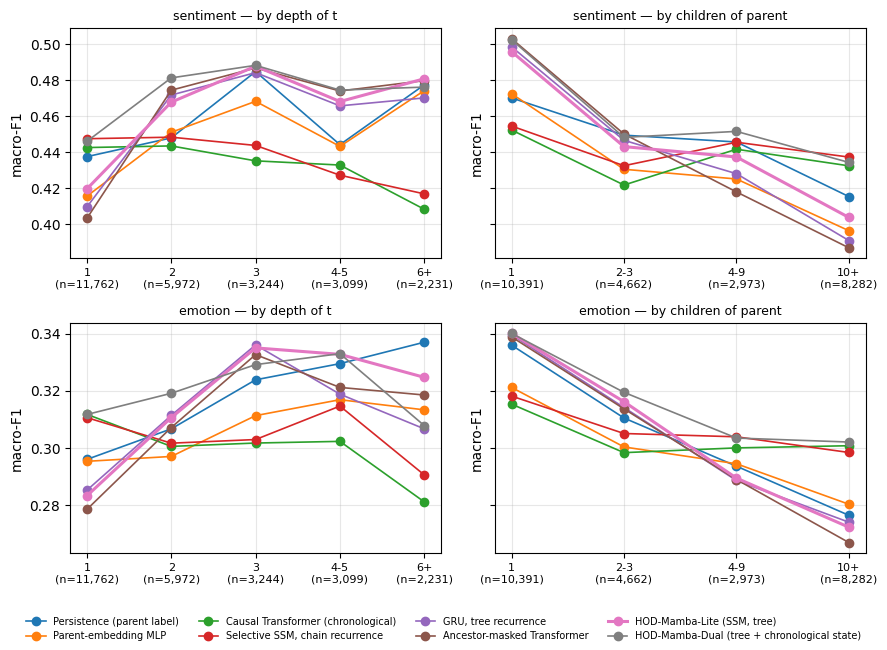

In [12]:
import matplotlib; import matplotlib.pyplot as plt
depth_t = np.array([test[i]["depth"][p] for i, p in zip(tix_ref, pos_ref)])
branch = np.array([test[i]["nchild"][test[i]["parent"][p]] for i, p in zip(tix_ref, pos_ref)])
dbin = np.digitize(depth_t, [2, 3, 4, 6]);  dlab = ["1", "2", "3", "4-5", "6+"]
bbin = np.digitize(branch, [2, 4, 10]);      blab = ["1", "2-3", "4-9", "10+"]
show = [m for m in ["persistence", "parent_mlp", "chain_transformer", "ssm_chain", "gru_tree", "anc_transformer", "ssm_tree", "ssm_dual"]
        if glob.glob(f"{OUT}/preds/{m}_s*.npz")]
recs = []
for m in show:
    preds = [dict(np.load(f)) for f in sorted(glob.glob(f"{OUT}/preds/{m}_s*.npz"))]
    for axis, bins, labs in (("depth", dbin, dlab), ("branching", bbin, blab)):
        for task, C, ky, kp in (("sentiment", N_S, "ys", "ps"), ("emotion", N_E, "ye", "pe")):
            vals = np.array([[f for f, _ in bucket_f1(p, bins, len(labs), C, ky, kp)] for p in preds])
            ns = [n for _, n in bucket_f1(preds[0], bins, len(labs), C, ky, kp)]
            for j, lab in enumerate(labs):
                recs.append(dict(model=m, axis=axis, task=task, bucket=lab, n=ns[j], f1=np.nanmean(vals[:, j])))
R = pd.DataFrame(recs); R.to_csv(f"{OUT}/f1_by_depth_branching.csv", index=False)
fig, axs = plt.subplots(2, 2, figsize=(9, 6.5), sharey="row")
for c, (axis, labs) in enumerate((("depth", dlab), ("branching", blab))):
    for r_, task in enumerate(("sentiment", "emotion")):
        ax = axs[r_, c]
        for m in show:
            d = R[(R.model == m) & (R.axis == axis) & (R.task == task)]
            ax.plot(range(len(labs)), d.f1, marker="o", lw=2.2 if m == "ssm_tree" else 1.2, label=LABEL.get(m, m))
        n = R[(R.model == show[0]) & (R.axis == axis) & (R.task == task)].n.tolist()
        ax.set_xticks(range(len(labs))); ax.set_xticklabels([f"{l}\n(n={k:,})" for l, k in zip(labs, n)], fontsize=8)
        ax.set_title(f"{task} — by {'depth of t' if axis == 'depth' else 'children of parent'}", fontsize=9)
        ax.set_ylabel("macro-F1"); ax.grid(alpha=.3)
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=7, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig(f"{OUT}/fig_f1_by_depth_branching.pdf"); plt.savefig(f"{OUT}/fig_f1_by_depth_branching.png", dpi=160); plt.show()


## 8. Gold-label check 


In [13]:
# ==== 8. Gold-label check (review item #8) ===========================================
GOLD_PATH = os.path.join(CONFIG["BASE_DIR"], "annotation", "gold_labels_consensus.parquet")
GOLD_ID_COL, GOLD_SENT_COL, GOLD_EMO_COL = None, None, None     # None = auto-detect (printed below)

# ---- reference: out-of-fold scores of the labelers (the honest label-quality estimate) ----
for cname in ("finetune_contract.json", "labeling_contract.json"):
    cpath = os.path.join(CONFIG["BASE_DIR"], "processed_v2", cname)
    if os.path.exists(cpath):
        cj = json.load(open(cpath, encoding="utf-8"))
        flat = pd.json_normalize(cj).T[0]
        keep = flat[[any(k in i.lower() for k in ("f1", "acc", "gold")) for i in flat.index]]
        print(f"{cname}:"); print(keep.to_string()); print()

gdf = pd.read_parquet(GOLD_PATH)
print(f"gold file: {GOLD_PATH}  ({len(gdf)} rows)\ncolumns: {list(gdf.columns)}")
def pick(cols, must, prefer, forbid=("prob", "score", "conf", "logit", "pred", "annotator_", "llm_", "_raw", "agree", "kappa")):
    cands = [c for c in cols if must in c.lower() and not any(f in c.lower() for f in forbid)]
    for p in prefer:
        hit = [c for c in cands if p in c.lower()]
        if hit: return hit[0]
    return cands[0] if cands else None
id_col = GOLD_ID_COL or ("doc_id" if "doc_id" in gdf.columns else pick(gdf.columns, "id", ["doc"], forbid=()))
gs_col = GOLD_SENT_COL or pick(gdf.columns, "sent", ["consensus", "gold", "final", "label"])
ge_col = GOLD_EMO_COL or pick(gdf.columns, "emo", ["consensus", "gold", "final", "label"])
print(f"using: id={id_col!r}  sentiment={gs_col!r}  emotion={ge_col!r}   (set GOLD_*_COL above if wrong)")
print("gold sentiment values:", gdf[gs_col].value_counts().to_dict())
print("gold emotion values:  ", gdf[ge_col].value_counts().to_dict())

g_s = encode_labels(gdf[gs_col], sent_classes)
g_e = encode_labels(gdf[ge_col], emo_classes, merge={"Fear": "Sadness"})
gold_by_doc = pd.DataFrame({"gs": g_s, "ge": g_e}, index=gdf[id_col].astype(str).to_numpy())
gold_by_doc = gold_by_doc[~gold_by_doc.index.duplicated()]

# ---- locate gold documents among the evaluated test positions ----------------------------
rows_t = np.array([test[i]["rows"][p] for i, p in zip(tix_ref, pos_ref)])
doc_t = ID_FRAME["doc_id"].to_numpy()[rows_t]
if (doc_t == "").all():
    raise RuntimeError("no doc_id mapping for embedding rows (see section 2); set CONFIG['CORPUS_PATH'] and re-run section 2")
inn = np.isin(doc_t, gold_by_doc.index.to_numpy())
all_rows = np.concatenate([t["rows"] for S in (train, val, test) for t in S])
all_docs = ID_FRAME["doc_id"].to_numpy()[all_rows]
print(f"\ngold docs found in the hyperedge dataset: {np.isin(gold_by_doc.index, all_docs).sum()} of {len(gold_by_doc)} "
      f"| on evaluated TEST positions: {inn.sum()} of {len(rows_t):,}")
if inn.sum() < 30:
    print("WARNING: fewer than 30 gold positions in the test period -- report this check as indicative only.")

gs = gold_by_doc.loc[doc_t[inn], "gs"].to_numpy(); ge = gold_by_doc.loc[doc_t[inn], "ge"].to_numpy()
ss, se = sent[rows_t[inn]], emo[rows_t[inn]]
match_s, match_e = (gs == ss)[gs >= 0].mean(), (ge == se)[ge >= 0].mean()
print(f"silver (training targets) == gold on these positions: sentiment {match_s:.1%}, emotion {match_e:.1%}")
if min(match_s, match_e) > 0.99:
    print("  -> the downstream labels keep the consensus labels for gold rows, so on these positions the silver targets\n"
          "     ARE the human labels. The check below is then a forecast-vs-human-label evaluation; label noise elsewhere\n"
          "     is bounded by the out-of-fold scores printed at the top of this cell.")

G = [dict(model="silver targets vs gold", sent_f1=macro_f1_from_cm(confusion(gs, ss, N_S))[0],
          emo_f1=macro_f1_from_cm(confusion(ge, se, N_E))[0], sent_f1_vs_silver=np.nan, emo_f1_vs_silver=np.nan, n=int(inn.sum()), seeds=0)]
for m in ["majority", "persistence", "thread_majority"] + list(runs.model.unique()):
    fs = sorted(glob.glob(f"{OUT}/preds/{m}_s*.npz"))
    if not fs: continue
    r = {"vs": [], "ve": [], "ss": [], "se": []}
    for f in fs:
        p = dict(np.load(f)); ps_, pe_ = p["ps"][inn], p["pe"][inn]
        r["vs"].append(macro_f1_from_cm(confusion(gs, ps_, N_S))[0]); r["ve"].append(macro_f1_from_cm(confusion(ge, pe_, N_E))[0])
        r["ss"].append(macro_f1_from_cm(confusion(ss, ps_, N_S))[0]); r["se"].append(macro_f1_from_cm(confusion(se, pe_, N_E))[0])
    G.append(dict(model=m, sent_f1=np.mean(r["vs"]), emo_f1=np.mean(r["ve"]), sent_f1_vs_silver=np.mean(r["ss"]),
                  emo_f1_vs_silver=np.mean(r["se"]), n=int(inn.sum()), seeds=len(fs)))
Gt = pd.DataFrame(G)
Gt.to_csv(f"{OUT}/gold_eval.csv", index=False)
display(Gt) if "display" in dir() else print(Gt.to_string())
if (Gt.model == "ssm_tree").any() and (Gt.model == "persistence").any():
    a, b = Gt.set_index("model").loc["ssm_tree"], Gt.set_index("model").loc["persistence"]
    print(f"\nOn human-labelled test positions: HOD-Mamba-Lite {a.sent_f1:.3f}/{a.emo_f1:.3f} vs persistence {b.sent_f1:.3f}/{b.emo_f1:.3f} "
          f"(sentiment/emotion, n={int(a.n)})")


finetune_contract.json:
nested_cv_results.sentiment.accuracy                0.6485
nested_cv_results.sentiment.macro_f1                0.6412
nested_cv_results.sentiment.per_class.Negative.f1   0.6961
nested_cv_results.sentiment.per_class.Neutral.f1    0.6220
nested_cv_results.sentiment.per_class.Positive.f1   0.6053
nested_cv_results.emotion.accuracy                  0.6168
nested_cv_results.emotion.macro_f1                  0.5258
nested_cv_results.emotion.per_class.Anger.f1        0.6559
nested_cv_results.emotion.per_class.Joy.f1          0.6205
nested_cv_results.emotion.per_class.Neutral.f1      0.6703
nested_cv_results.emotion.per_class.Sadness.f1      0.4192
nested_cv_results.emotion.per_class.Surprise.f1     0.2632

labeling_contract.json:
gold_path                               /content/drive/MyDrive/PhD/reddit_opinion_rese...
gold_class_counts.sentiment.Negative                                                  374
gold_class_counts.sentiment.Neutral                            

## 9. Training cost per model 

In [14]:
cost = runs.groupby("model").agg(sec_per_epoch=("sec_per_epoch", "mean"), best_epoch=("best_epoch", "mean"),
                                 epochs_run=("epochs_run", "mean"), train_minutes=("train_seconds", lambda s: s.mean() / 60),
                                 peak_mem_mb=("peak_mem_mb", "max"), n_params=("n_params", "first")).reset_index()
cost.to_csv(f"{OUT}/training_cost.csv", index=False); display(cost) if "display" in dir() else print(cost)


                 model  sec_per_epoch  best_epoch  epochs_run  train_minutes  \
0      anc_transformer         3.1427      5.4000     10.4000         0.5442   
1    chain_transformer         3.0206      6.8000     11.8000         0.5932   
2          gat_topdown         2.5876      7.4000     12.4000         0.5347   
3            gru_chain        12.7340      6.0000     11.0000         2.3349   
4             gru_tree         6.4662      4.2000      9.2000         0.9908   
5           parent_mlp         1.0769      5.6000     10.6000         0.1901   
6            ssm_chain         8.6597      7.4000     12.4000         1.7879   
7             ssm_dual        15.0897      5.4000     10.4000         2.6150   
8             ssm_tree         7.5424      7.8000     12.8000         1.6093   
9   ssm_tree_cleanfeat         7.5921      8.4000     13.4000         1.6928   
10     ssm_tree_hetero         7.1010      9.2000     14.2000         1.6806   
11      ssm_tree_leaky         7.5893   

## 10. Summary 

In [15]:
def get(m, col):
    r = T[T.model == m]; return float(r[col].iloc[0]) if len(r) else float("nan")
ps_, ss_ = get("persistence", "sent_mean"), get(REF, "sent_mean")
print(f"Persistence vs HOD-Mamba-Lite (sentiment): {ps_:.3f} vs {ss_:.3f}  (gap {ss_ - ps_:+.3f})")
print("  -> DECISION:", "forecasting stays a headline claim" if ss_ - ps_ >= 0.02 else "reframe forecasting as supporting evidence")
print(f"Majority -> Lite ratio (sentiment/emotion): {ss_ / get('majority','sent_mean'):.2f}x / {get(REF,'emo_mean') / get('majority','emo_mean'):.2f}x")
print(f"Lite vs Hetero ({len(CONFIG['SEEDS'])} seeds): sentiment {ss_:.3f} vs {get('ssm_tree_hetero','sent_mean'):.3f}; "
      f"emotion {get(REF,'emo_mean'):.3f} vs {get('ssm_tree_hetero','emo_mean'):.3f}; p = {get('ssm_tree_hetero','p_sent'):.3f} / {get('ssm_tree_hetero','p_emo'):.3f}")
print(f"Dual (tree + chronological) vs Lite: sentiment {get('ssm_dual','sent_mean'):.3f} vs {ss_:.3f}; emotion {get('ssm_dual','emo_mean'):.3f} vs {get(REF,'emo_mean'):.3f}")
print(f"Author features (sentiment / emotion): none {ss_:.3f}/{get(REF,'emo_mean'):.3f} | leak-free {get('ssm_tree_cleanfeat','sent_mean'):.3f}/{get('ssm_tree_cleanfeat','emo_mean'):.3f} "
      f"| notebook-04 (leaky) {get('ssm_tree_leaky','sent_mean'):.3f}/{get('ssm_tree_leaky','emo_mean'):.3f}")
print(f"  -> notebook 05-08 numbers vs the final leak-free setup: {get('ssm_tree_leaky','sent_mean') - ss_:+.3f} sentiment, "
      f"{get('ssm_tree_leaky','emo_mean') - get(REF,'emo_mean'):+.3f} emotion")
print(f"Dual vs persistence (sentiment / emotion): {get('ssm_dual','sent_mean') - get('persistence','sent_mean'):+.3f} / "
      f"{get('ssm_dual','emo_mean') - get('persistence','emo_mean'):+.3f}  (CIs in section 6b)")
best_other = T[~T.model.isin([REF, "ssm_tree_hetero", "ssm_dual", "ssm_tree_nofeat", "ssm_tree_leaky", "ssm_tree_cleanfeat"])].sort_values("sent_mean").iloc[-1]
print(f"Strongest non-HOD model (sentiment): {best_other.model} {best_other.sent_mean:.3f}")
print("Artifacts written to", OUT, ":", sorted(os.listdir(OUT)))


Persistence vs HOD-Mamba-Lite (sentiment): 0.452 vs 0.458  (gap +0.007)
  -> DECISION: reframe forecasting as supporting evidence
Majority -> Lite ratio (sentiment/emotion): 2.31x / 3.41x
Lite vs Hetero (5 seeds): sentiment 0.458 vs 0.456; emotion 0.314 vs 0.312; p = 0.544 / 0.639
Dual (tree + chronological) vs Lite: sentiment 0.473 vs 0.458; emotion 0.325 vs 0.314
Author features (sentiment / emotion): none 0.458/0.314 | leak-free 0.451/0.293 | notebook-04 (leaky) 0.468/0.322
  -> notebook 05-08 numbers vs the final leak-free setup: +0.010 sentiment, +0.008 emotion
Dual vs persistence (sentiment / emotion): +0.021 / +0.011  (CIs in section 6b)
Strongest non-HOD model (sentiment): treelstm_topdown 0.463
Artifacts written to /content/drive/MyDrive/PhD/reddit_opinion_research/processed_v2/results/nb09_v4 : ['bootstrap_pairs.csv', 'bootstrap_vs_ssm_tree.csv', 'f1_by_depth_branching.csv', 'fig_f1_by_depth_branching.pdf', 'fig_f1_by_depth_branching.png', 'gold_eval.csv', 'preds', 'runs.csv'